## FEED FORWARD CLASSIFICATION

# Dependencies

In [1]:
#Importing Libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibilty

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Data Generation

**Variables of interest** :
- P is the number of patterns (clusters)
- N_s is the number of stimulus neurons (features per pattern)
- V number of variations across centers for each pattern


**Generation of central S- patterns:**
1) data_generation1.py 
2) data_generation2.py

**Generation of noisy variants** : generate_var.py


**$\Delta S$** : delta_s.py

$\Delta S =\frac{2}{N_S} \sum_{i=1}^{N_S} \mathbb{E} \left[ \left| \bar{S}_i^m - S_i^m \right| \right]$

The code ensures that the variables center and samples are converted into NumPy arrays of type float, with center also being flattened into a 1D array.

# Generate net inputs and threshold

The `compute_global_threshold` function computes a global threshold **T** that determines cortical sparsity across all patterns.

### Purpose:
Control the fraction of cortical neurons that are active (sparse coding) by setting an appropriate threshold for binary activation.

### Parameters:
- **`central_patterns`**: Original cluster centers, shape `(P, N_s)`
- **`noisy_patterns`**: Noisy variations, shape `(P × V, N_s)`  
- **`J`**: Synaptic weight matrix, shape `(N_c, N_s)`
- **`f`**: Desired cortical sparsity (fraction of active neurons)

In [6]:
# Function to compute global threshold from all patterns, both central and noisy
def compute_global_threshold(central_patterns, noisy_patterns, J, f):
    """
    Computes global threshold T from all h_mj values for central and noisy patterns.

    Parameters:
        central_patterns: shape (P, N_s)
        noisy_patterns : shape (P * V, N_s)
        J: synaptic weight matrix (N_c, N_s)
        f: desired cortical sparsity

    Returns:
        T such that only top f fraction of all h_mj are above it
    """
    h_all = []

    # Central patterns net input
    for center in central_patterns:
        # here, center is NOT shape (1, 2) it is a 1D array of shape (2,)
        h_center = J @ (center - 0.5) #shape: N_c
        h_all.append(h_center) #list of vectors

    # Noisy patterns net inputs
    for noisy in noisy_patterns:
        h_noisy = J @ (noisy - 0.5)
        h_all.append(h_noisy)

    # Flatten all h values from all neurons across all patterns
    h_all = np.concatenate(h_all)
    T = np.percentile(h_all, 100 * (1 - f)) #It sets the threshold T such that only the top f fraction of the values in h_all are greater than or equal to T
    return T

In [7]:
#Threshold computation considering only central patterns
def compute_global_threshold_central_only(central_patterns, J, f):
    h_all = []
    for center in central_patterns:      # shape (P, N_s)
        h_center = J @ (center - 0.5)    # shape (N_c,)
        h_all.append(h_center)
    h_all = np.concatenate(h_all)        # length P*N_c
    T = np.percentile(h_all, 100 * (1 - f))
    return T


# Cortical patterns - Heaviside Activation Function

Cortical patterns - BABADI

In [5]:
def compute_cortical_patterns(patterns, J, T):
    """
    Compute cortical binary activity patterns from input patterns.

    Parameters:
        patterns: shape (num_patterns, N_s), binary input patterns
        J: synaptic weight matrix, shape (N_c, N_s)
        T: global threshold

    Returns:
        np.array: cortical binary patterns, shape (num_patterns, N_c)
    """
    centered_inputs = patterns - 0.5
    h = centered_inputs @ J.T     # shape: (num_patterns, N_c)
    C = (h >= T).astype(int)
    return C,h

Check cortical patterns computation

In [37]:
# Define the stimulus pattern S
S = np.array([[1, 0]])  # shape (1, 2)

#noisy variations
noisy_patterns = np.array([
    [1, 0],
    [0, 1],
    [1, 1],
    [0, 0]
])  # shape (4, 2)

# Define the synaptic weight matrix J (N_c = 4)
J = np.array([
    [1, 2],
    [-1, 0.5],
    [0.5, -0.5],
    [2, -1]
])  # shape (4, 2)

# Define the threshold
T = 0

# Compute the cortical pattern and net input h
C, h = compute_cortical_patterns(S, J, T)

# Display results
print("Net inputs h:\n", h)
print("Cortical response C:\n", C)

h_all = []

# Central patterns net input
for center in S:
    # here, center is NOT shape (1, 2) it is a 1D array of shape (2,)
    h_center = J @ (center - 0.5) #shape: N_c
    h_all.append(h_center) #list of vectors

# Noisy patterns net inputs
for noisy in noisy_patterns:
    h_noisy = J @ (noisy - 0.5)
    h_all.append(h_noisy)

#print("h_noisy:", h_all)
#print("Number of h vectors:", len(h_all))
# Flatten all h values from all neurons across all patterns
h_all = np.concatenate(h_all)
#print("h_all:", h_all)
#Check threshould function
#T_comp= compute_global_threshold(S, noisy_patterns, J, 0.5)
#print("T_comp", T_comp)

Net inputs h:
 [[-0.5  -0.75  0.5   1.5 ]]
Cortical response C:
 [[0 0 1 1]]
h_noisy: [array([-0.5 , -0.75,  0.5 ,  1.5 ]), array([-0.5 , -0.75,  0.5 ,  1.5 ]), array([ 0.5 ,  0.75, -0.5 , -1.5 ]), array([ 1.5 , -0.25,  0.  ,  0.5 ]), array([-1.5 ,  0.25,  0.  , -0.5 ])]
Number of h vectors: 5
h_all: [-0.5  -0.75  0.5   1.5  -0.5  -0.75  0.5   1.5   0.5   0.75 -0.5  -1.5
  1.5  -0.25  0.    0.5  -1.5   0.25  0.   -0.5 ]


# BABADI PLOTS

#Stimulus cluster size and cortical cluster size

In [3]:
def compute_delta_c_1(center_cortical, noisy_corticals, f):
    """
    Compute cortical cluster size ΔC based on noisy and central cortical patterns.

    Parameters:
        central_corticals: shape (P, N_c), cortical codes for cluster centers
        noisy_corticals: shape (P * V, N_c), cortical codes for noisy variants
        full_labels: shape (P * V,), maps each noisy pattern to its cluster index
        f: sparseness level
    """
    center_cortical = np.asarray(center_cortical).astype(int)
    #center_cortical = np.asarray(center_cortical).astype(int).ravel()
    noisy_corticals = np.asarray(noisy_corticals).astype(int)
    Nc = center_cortical.size
    diffs = [np.sum(np.abs(sample - center_cortical)) for sample in noisy_corticals] #Hamming distance: counts how many 0/1 mismatches there are
    avg_diff = np.mean(diffs)
    epsilon = 1e-8
    delta_c = avg_diff / (2 * Nc * f * (1 - f) + epsilon)

    # Normalize by 2 * N_C * f * (1 - f)
    #delta_c = avg_diff / (2 * Nc* f * (1 - f))
    return delta_c

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s
np.random.seed(42)

# Parameters
P = 10         # Number of clusters
V = 500        # Variations per pattern
N_s = 1000     # Input neurons
N_r = 10000     # Cortical neurons
f_values = np.array([0.001, 0.01, 0.05])  # Different sparsity levels
DS_values = np.linspace(0, 1 , 10)    # Different flip probabilities (DS ~ flip_prob)
flip_prob=DS_values/2
# Generate central patterns
y = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_s)

# Initialize Weights (Normal distribution)
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
colors = ['#E03A2A', '#426BAF', '#000000']

plt.figure(figsize=(8, 5))

# Loop through sparsity levels
for i, f in enumerate(f_values):
    DC = [] # <--- CRITICAL FIX: Reset list for each 'f' loop
    
    print(f"Processing sparsity f={f}...")
    
    for flip in flip_prob:
        # Generate noisy inputs
        noisy_patterns, _, _ = generate_variations(central_patterns, y, V, flip)
        
        # Compute Threshold for this sparsity level
        T = compute_global_threshold(central_patterns, noisy_patterns, J, f)
        
        # Compute Cortical Responses
        central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)
        noisy_corticals, _ = compute_cortical_patterns(noisy_patterns, J, T)
        
        # Compute Delta C (Distance in cortical space)
        # Note: central_corticals[0] assumes P=1. If P>1, this logic needs adjustment.
        delta_c = compute_delta_c_1(central_corticals[0], noisy_corticals, f)
        DC.append(delta_c)

    # Plotting for this specific f value
    # Use standard plot first, verify logic, then customize
    plt.plot(DS_values, DC, marker='o', color=colors[i % len(colors)], label=f"f = {f:.3f}")
# Final Plot Formatting
plt.title(f"Cortical Cluster Size vs Stimulus Variation (N_R={N_r})")
plt.xlabel("Stimulus cluster size ΔS (Flip Prob)")
plt.ylabel("Cortical cluster size ΔC")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Processing sparsity f=0.001...


KeyboardInterrupt: 

<Figure size 800x500 with 0 Axes>

1.1687504639596158
1.1687504639596158
1.1687504639596158
1.1687504639596158
1.1687504639596158
1.1687504639596158
1.1687504639596158
1.1687504639596158
1.1687504639596158
1.1687504639596158
DC for f=0.05: [np.float64(0.0), np.float64(0.3860421052590943), np.float64(0.5374947368364474), np.float64(0.6491157894668513), np.float64(0.7442105263079557), np.float64(0.8185894736755938), np.float64(0.8707368420960976), np.float64(0.9227368420955502), np.float64(0.9638526315688015), np.float64(0.9886736842001193)]


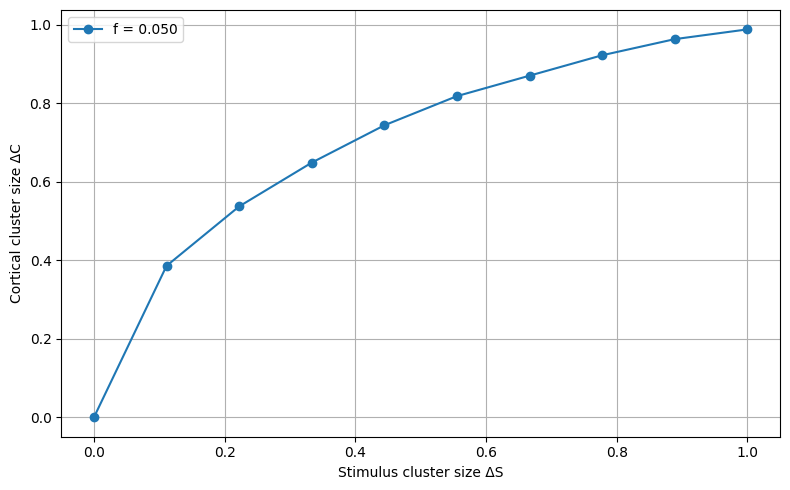

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s
np.random.seed(42)

# Parameters
P = 1         # Number of clusters
V = 50        # Variations per pattern
N_s = 1000     # Input neurons
N_r = 10000     # Cortical neurons
f_values = np.array([0.001, 0.01, 0.05])  # Different sparsity levels
DS_values = np.linspace(0, 1 , 10)    # Different flip probabilities (DS ~ flip_prob)
flip_prob=DS_values/2

# Generate central patterns (same across DS)
y = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_s)
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
DC=[]

plt.figure(figsize=(8, 5))
DC = []
f=0.05
for flip in flip_prob:
    noisy_patterns,_,_ = generate_variations(central_patterns, y, V, flip)
    T = compute_global_threshold_central_only(central_patterns, J, f)
    print(T)
    central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)
    noisy_corticals, _= compute_cortical_patterns(noisy_patterns, J, T)
    diff=[np.sum(np.abs(sample - central_corticals)) for sample in noisy_corticals]
    delta_c = compute_delta_c_1(central_corticals, noisy_corticals, f)
    DC.append(delta_c)
print(f"DC for f={f}: {DC}")
plt.plot(DS_values, DC ,marker='o',label=f"f = {f:.3f}")

# Plotting
plt.xlabel("Stimulus cluster size ΔS")
plt.ylabel("Cortical cluster size ΔC")
plt.grid(True)
plt.legend()
plt.tight_layout()

**Comparing the case of threshold over all patterns and threshold over central only**:

Noisy patterns are built as perturbations of the central ones then the distributions of $h_j^m$ over central and noisy patterns will be very close.
Since h=J(S−0.5) is linear, a small perturbation of S becomes a small perturbation in h

#Fraction of active neurons f and cortical cluster size $\Delta C$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_s import compute_delta_s
from delta_c import compute_delta_c

np.random.seed(42)

# Parameters
P = 1               # Number of clusters
V = 50              # Variations per pattern
N_s = 1000          # Input neurons
N_r = 10000         # Cortical neurons
f_values = np.linspace(0.001, 0.5, 10)   # Sparsity values (avoid f=0)
DS_values = np.array([0.1,0.2,0.3])                               # Fixed ΔS
flip_values = DS_values / 2                          # Corresponding flip probability

# Generate data
y = np.arange(P)
central_patterns = generate_central_patterns(P, N_s)
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))


plt.figure(figsize=(8, 5))
# Compute ΔC for each f
#colors = ['red', 'blue', 'black']ù
colors = [ '#E03A2A','#426BAF','#000000']
for i, DS in enumerate(DS_values):
    flip = DS / 2
    DC = []
    for f in f_values:
        # Generate noisy patterns once
        noisy_patterns, _, _ = generate_variations(central_patterns, y, V, flip)
        T = compute_global_threshold(central_patterns, noisy_patterns, J, f)
        central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)
        noisy_corticals, _ = compute_cortical_patterns(noisy_patterns, J, T)
        delta_c = compute_delta_c_1(central_corticals, noisy_corticals, f)
        DC.append(delta_c)

    # Plotting
    plt.plot(f_values, DC, marker='o', color=colors[i], label=f"ΔS = {DS:.2f}")

plt.xlabel("Sparsity $f$")
plt.ylabel("Cortical cluster size $\\Delta_C$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


IndexError: index 1 is out of bounds for axis 0 with size 1

<Figure size 800x500 with 0 Axes>

**Net input and probability density for a central pattern**

The sparseness amplifies the sensibility to inputs, increasing the size of Dc, that is the fraction of neurons that invert their state between the central pattern and a noisy variant



PYTHON IN USO: c:\Users\letiz\Documents\MASTER\TESI\FF_classification_2307\.venv\Scripts\python.exe


C:\Users\letiz\AppData\Local\Temp\ipykernel_28936\3828476788.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


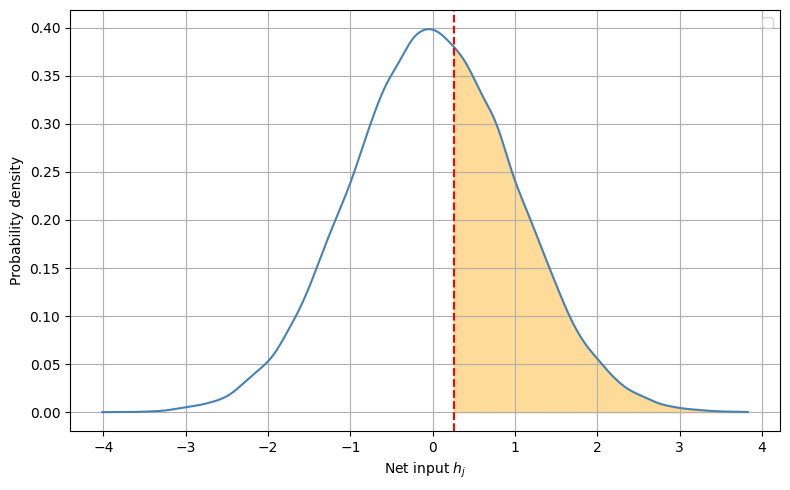

In [31]:
import sys; print("PYTHON IN USO:", sys.executable)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

# Parameters
P = 1
V = 0
N_s = 10000
N_r = 50000
f = 0.4
DS = 0.1
flip_prob = DS / 2

np.random.seed(42)

# Generate data
central_patterns = generate_central_patterns(P, N_s)
y = np.arange(P)
noisy_patterns, _ ,_= generate_variations(central_patterns, y, V, flip_prob)
all_patterns = np.vstack([central_patterns] + [noisy_patterns])

# Synaptic weights
J = np.random.normal(0, 2/np.sqrt(N_s), size=(N_r, N_s))

# Compute h values
centered_input = all_patterns - 0.5
h = centered_input @ J.T  # shape: (num_patterns, N_r)
h_values = h.flatten()

# Compute threshold T for sparsity f
T = np.percentile(h_values, 100 * (1 - f))

# Estimate density using KDE
kde = gaussian_kde(h_values)
x_vals = np.linspace(np.min(h_values), np.max(h_values), 1000)
pdf_vals = kde(x_vals)

# Plot PDF curve
plt.figure(figsize=(8, 5))
plt.plot(x_vals, pdf_vals, color="steelblue")

# Add vertical line at threshold T
plt.axvline(T, color='red', linestyle='--')

# Shade area to the right of T (active neurons)
x_shade = x_vals[x_vals >= T]
y_shade = pdf_vals[x_vals >= T]
plt.fill_between(x_shade, y_shade, color='orange', alpha=0.4)

# Plot
plt.xlabel("Net input $h_j$")
plt.ylabel("Probability density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [35]:
print("mean(S_i - 0.5) =", centered_input.mean())
print("empirical mean h:", h_values.mean())

mean(S_i - 0.5) = -0.002
 empirical mean h: -1.9043047512774716


The KDE curve shifts left or right by an amount equal to the empirical mean $\bar h = \frac{\sum_{i=1}^{N_r} h_j}{N_r}$


1.6650617495264641
1.6630393882237555
1.6503813931090392
1.6495953997580193
1.6477852439507445
1.6443323651264807
1.6431131133483163
1.6419822862071165
1.6473960914431434
1.646867037344785
DC for f=0.01: [np.float64(0.0), np.float64(0.49929292926771246), np.float64(0.6924242423892715), np.float64(0.8021212120807009), np.float64(0.8786868686424905), np.float64(0.9476767676289051), np.float64(0.99585858580829), np.float64(1.0248484847967247), np.float64(1.0304040403519998), np.float64(1.0421212120685797)]
1.1687504639595994
1.1678711587868718
1.1673314454720765
1.160959633473058
1.1594764163365539
1.1615806135206868
1.1630668527854242
1.1611125023230189
1.163577885039007
1.1620581640395105
DC for f=0.05: [np.float64(0.0), np.float64(0.38534736841699635), np.float64(0.5499157894678955), np.float64(0.6673263157824493), np.float64(0.7587157894656977), np.float64(0.8343578947280593), np.float64(0.8879999999906526), np.float64(0.9410736842006202), np.float64(0.9793473684107437), np.float64(1.

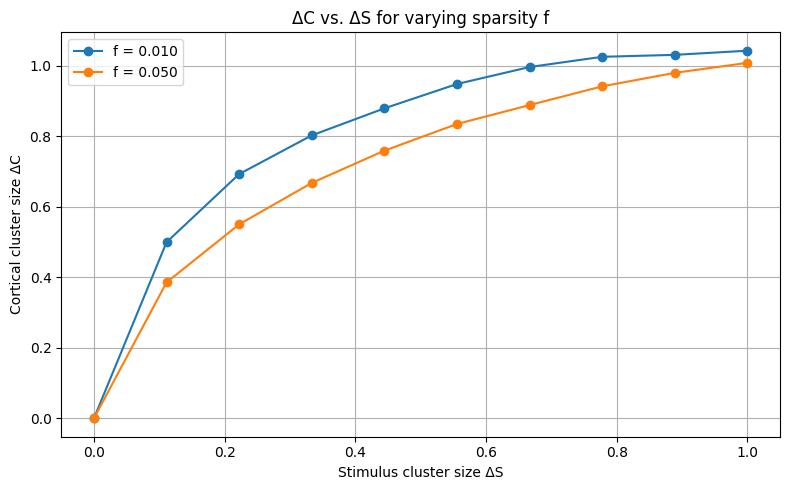

In [17]:
import sys; print("PYTHON IN USO:", sys.executable)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

# Parameters
P = 1
V = 50
N_s = 1000
N_r = 10000
f = 0.2
DS = 0.1
flip_prob = DS / 2

np.random.seed(42)

# Generate data
central_patterns = generate_central_patterns(P, N_s)
y = np.arange(P)
noisy_patterns, _ ,_= generate_variations(central_patterns, y, V, flip_prob)
all_patterns = np.vstack([central_patterns, noisy_patterns])

# Synaptic weights - CORRECT DIMENSIONS
J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))  # Shape: (10000, 1000)

print(f"all_patterns shape: {all_patterns.shape}")
print(f"J shape: {J.shape}")
print(f"J.T shape: {J.T.shape}")

# Compute h values
centered_input = all_patterns - 0.5
h = centered_input @ J.T  # shape: (num_patterns, N_r)
h_values = h.flatten()

# Compute threshold T for sparsity f
T = np.percentile(h_values, 100 * (1 - f))

# Estimate density using KDE
kde = gaussian_kde(h_values)
x_vals = np.linspace(np.min(h_values), np.max(h_values), 1000)
pdf_vals = kde(x_vals)

# Plot PDF curve
plt.figure(figsize=(8, 5))
plt.plot(x_vals, pdf_vals, color="steelblue")

# Add vertical line at threshold T
plt.axvline(T, color='red', linestyle='--')

# Shade area to the right of T (active neurons)
x_shade = x_vals[x_vals >= T]
y_shade = pdf_vals[x_vals >= T]
plt.fill_between(x_shade, y_shade, color='orange', alpha=0.4)

# Plot
plt.xlabel("Net input $h_j$")
plt.ylabel("Probability density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# PERCEPTRON CLASSIFICATION

1. `train_perceptron` Function

This function implements the classic perceptron learning algorithm for binary classification.

**Key Components:**

- **Input centering**: `x_mu - f` centers cortical patterns around their mean activity
- **Weight initialization**: `W = np.random.normal(0, 1/√N_r)` uses small random weights scaled by neuron count
- **Perceptron rule**: Updates weights only when prediction is wrong

**Training Loop:**
```python
y_pred = np.sign(np.dot(x_mu - f, W))  # Make prediction
if y_mu * np.dot((x_mu-f), W) <= 0:    # Check if wrong
    W += eta * y_mu * x_mu             # Update weights
```

**Why centering matters**: Subtracting `f` (mean activity) ensures the decision boundary passes through the origin of the centered space, improving learning stability.

2. `test_perceptron` Function

Tests the trained perceptron on new data.

- **Output**: Classification error rate (fraction of misclassified samples)

3. `compute_theoretical_classification_error` Function

Computes the theoretical lower bound on classification error.


**Version using only central patterns**

In [40]:
def train_perceptron(central_patterns, labels, f, epochs, eta):
    """
    Trains a perceptron on central cortical patterns only (Babadi-style).

    Parameters:
        central_patterns (ndarray): shape (P, N_r), cortical codes for central patterns
        labels (ndarray): shape (P,), target labels in {-1, +1}
        f (float): average activity (sparsity level)
        epochs (int): number of epochs to train
        eta (float): learning rate

    Returns:
        W (ndarray): learned weight vector (shape: N_r)
    """
    P, N_r = central_patterns.shape
    W = np.random.normal(0, 1 / np.sqrt(N_r), size=N_r)  # Init weights

    for epoch in range(epochs):
        errors = 0
        for mu in np.random.permutation(P):
            x_mu = central_patterns[mu] - f  # center the input
            y_mu = labels[mu]
            y_pred = np.sign(np.dot(x_mu, W))
            if y_pred == 0:
                y_pred = 1
            if y_mu * np.dot(x_mu, W) <= 0:  # misclassified
                W += eta * y_mu * x_mu
                errors += 1
        if errors == 0:
            break
    return W
def test_perceptron(test_patterns, labels, W, f):
    """
    Tests perceptron on test patterns (typically noisy cortical codes).

    Parameters:
        test_patterns (ndarray): shape (num_samples, N_r)
        labels (ndarray): true labels
        W (ndarray): trained weights
        f (float): sparsity level used for centering

    Returns:
        float: classification error
    """
    centered_test = test_patterns - f
    preds = np.sign(centered_test @ W)
    preds[preds == 0] = 1
    error = 1 - np.mean(preds == labels)
    return error


## `run_threshold` Function

Evaluate perceptron classification performance across different sparsity levels to find the optimal threshold for cortical activity.

**Measure Actual Sparsity:**
   ```python
   f_active = np.mean(A_R)
   ```
   - Computes fraction of neurons actually active
   - This is the empirical sparsity achieved by threshold T

**Returns:**
- **`fractions_active`**: Actual sparsity levels achieved at each threshold
- **`misclassification_rates`**: Classification errors at each sparsity level

In [41]:
#Thresholding and classification
#how well the perceptron can distinguish between different stimulus patterns after projecting them to produce sparse binary cortical representations
#for a range of threshold values 𝑇

def run_threshold(all_patterns, labels, central_patterns, central_labels, N_r, N_s, epochs, eta, thresholds):
    J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
    fractions_active = []
    misclassification_rates = []

    for T in thresholds:
        A_R, _ = compute_cortical_patterns(all_patterns, J, T)  # all = central + noisy
        central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)

        f_active = np.mean(A_R)  # overall sparsity
        fractions_active.append(f_active)

        # Train only on central patterns
        W = train_perceptron(central_corticals, central_labels, f_active, epochs, eta)

        # Test on all patterns
        error = test_perceptron(A_R, labels, W, f_active)
        misclassification_rates.append(error)

    return fractions_active, misclassification_rates

In [45]:
#plotting
def plot_smoothed_results(fractions_active, misclassification_rates, window_size=5):
    smoothed_error = np.convolve(misclassification_rates, np.ones(window_size)/window_size, mode='valid')
    plt.figure(figsize=(8, 5))
    plt.plot(fractions_active[:len(smoothed_error)], smoothed_error * 100, marker='o',lw=2)
    plt.xlabel('Sparsity $f$ (fraction active in cortical layer)')
    plt.ylabel('% Misclassification')
    plt.title('Perceptron classification vs. sparsity $f$')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


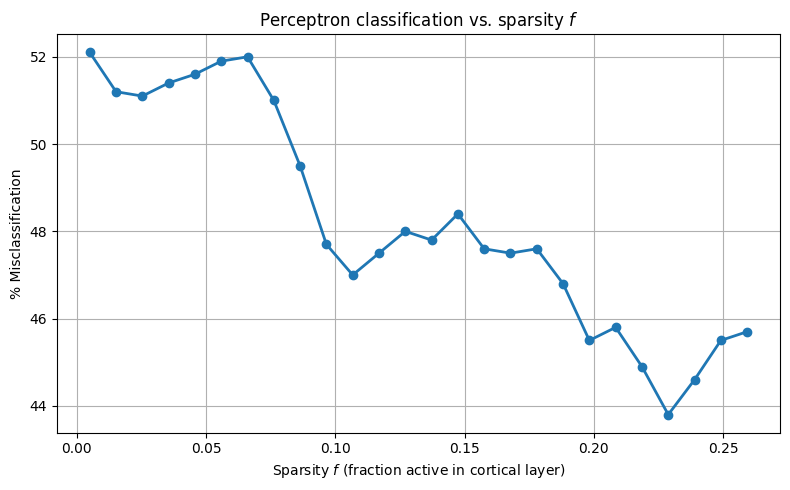

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from sklearn.model_selection import train_test_split

# Parameters
P = 1000             # Number of clusters
N_C = 10000         # Cortical neurons
N_S = 1000          # Stimulus neurons
Delta_S = 0.1       # Fixed stimulus cluster size
epochs = 100     # Perceptron training epochs
eta = 0.001        # Learning rate
# Simulate Input patterns
# Generate random labels in {-1, +1}
central_labels = np.random.choice([-1, 1], size=P)

# Generate central patterns 1
central_patterns= generate_central_patterns(P, N_S)
# synaptic weights
J = np.random.normal(0, 2 / np.sqrt(N_S), size=(N_C, N_S))

# Sweep over sparsity values
f_values = np.linspace(0.005, 0.3, 30)
errors = []

for f in f_values:
    T = compute_global_threshold_central_only(central_patterns, J, f)
    # cortical patterns
    central_corticals,h_c = compute_cortical_patterns(central_patterns, J, T)
    X_train, X_test, y_train, y_test = train_test_split(
    central_corticals, central_labels, test_size=0.2, random_state=0)
    # Train only on central patterns
    W = train_perceptron(X_train, y_train, f, epochs=epochs, eta=eta)
    # Test on all patterns
    error = test_perceptron(X_test, y_test, W, f)
    errors.append(error)

plot_smoothed_results(f_values, errors, window_size=5)


# Simulation considering theoretical error

In [10]:
from scipy.stats import norm
#Signal-to-Noise Ratio (SNR) and theoretical classification error
def compute_theoretical_classification_error(delta_C, f, P, N_C, N_S):
    alpha_C = P / N_C
    alpha_S = P / N_S
    Q = 2 * f * np.abs(np.log(f))
    SNR = (1 - delta_C)**2 / (alpha_C + alpha_S * Q**2)
    epsilon = norm.sf(np.sqrt(SNR))  # H(x) = tail of standard normal
    return epsilon

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations
from delta_c import compute_delta_c

# Parameters
P = 1000             # Number of clusters
N_C = 10000         # Cortical neurons
N_S = 1000          # Stimulus neurons
Delta_S = 0.2       # Fixed stimulus cluster size
V =50
flip_prob = Delta_S / 2  # Corresponding flip probability

# Simulate Input patterns
# Generate random labels in {-1, +1}
labels = np.random.choice([-1, 1], size=P)

# Generate central patterns 1
central_patterns= generate_central_patterns(P, N_S)
# Generate variations
noisy_patterns, full_labels, checks = generate_variations(central_patterns, labels, V, flip_prob)
# synaptic weights
J = np.random.normal(0, 2 / np.sqrt(N_S), size=(N_C, N_S))

# Sweep over sparsity values
f_values = np.linspace(0.005, 0.1, 20)
errors = []

for f in f_values:
    T = compute_global_threshold(central_patterns, noisy_patterns, J, f)

    # cortical patterns
    central_corticals, h_c = compute_cortical_patterns(central_patterns, J, T)
    noisy_corticals,   h_n = compute_cortical_patterns(noisy_patterns,   J, T)

    # pass full_labels here
    delta_C = compute_delta_c(central_corticals, noisy_corticals, full_labels, f)

    eps = compute_theoretical_classification_error(delta_C, f, P, N_C, N_S)
    errors.append(eps)

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(f_values, errors, marker='o', lw=2)
plt.xlabel("Sparsity $f$")
plt.ylabel("Theoretical classification error $\\varepsilon$")
plt.title("Theoretical error vs. sparsity $f$ (ΔS = 0.2)")
plt.grid(True)
plt.tight_layout()
plt.show()


KeyboardInterrupt: 

# 1. Simulation considering noisy patterns and deltaS_learn=0.1

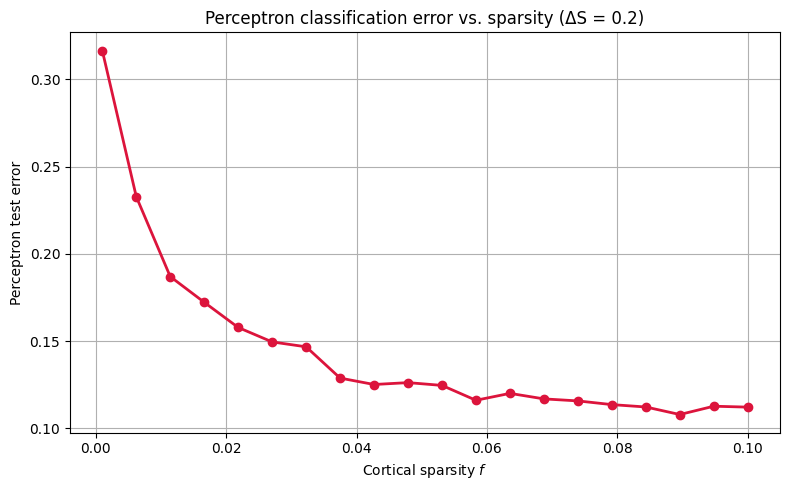

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

# ----------------------------
# Parameters
# ----------------------------
P = 1000       # Number of clusters
N_S = 1000       # Sensory neurons
N_C = 10000      # Cortical neurons
V_train = 10     # Noisy patterns per cluster (training)
V_test = 25      # Noisy patterns per cluster (testing)
epochs = 100     # Perceptron training epochs
eta = 0.001      # Learning rate

deltaS_train = 0.1
deltaS_test = 0.2

flip_prob_train = deltaS_train / 2
flip_prob_test = deltaS_test / 2

f_vals = np.linspace(0.001, 0.1, 20)
errors = []

# Random seed for reproducibility
np.random.seed(42)

#Generate central patterns

labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Generate noisy training patterns (ΔS = 0.1)
noisy_train, train_labels, _ = generate_variations(central_patterns, labels, V_train, flip_prob_train)

# Generate noisy test patterns (ΔS = 0.2)
noisy_test, test_labels, _ = generate_variations(central_patterns, labels, V_test, flip_prob_test)

# Random projection matrix J
J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))  # shape: (N_C, N_S)

# For each sparsity level f
for f in f_vals:
    # Threshold
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # cortical patterns for training
    train_cortical, _ = compute_cortical_patterns(noisy_train, J, T)

    # cortical test patterns
    test_cortical, _ = compute_cortical_patterns(noisy_test, J, T)

    # TRAINING perceptron on noisy cortical patterns
    N_samples, N_r = train_cortical.shape
    W = np.random.normal(0, 1 / np.sqrt(N_r), size=N_r) #initialize weight vector W randomly
    for epoch in range(epochs):
        errs = 0
        for mu in np.random.permutation(N_samples):
            x = train_cortical[mu]
            y = train_labels[mu]
            x_centered = x - f  # center
            y_pred = np.sign(np.dot(W, x_centered))
            if y_pred == 0:
                y_pred = 1
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x
                errs += 1
        if errs == 0: #Se non ci sono errori vuol dire che il perceptron classifica correttamente tutti i pattern di training.


            break

    # Test on noisy cortical patterns
    preds = np.sign((test_cortical - f) @ W)
    preds[preds == 0] = 1
    error = 1 - np.mean(preds == test_labels) #percentage of correct predictions
    errors.append(error)

# Plotting 
plt.figure(figsize=(8, 5))
plt.plot(f_vals, errors, marker='o', lw=2, color='crimson')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Perceptron test error")
plt.title("Perceptron classification error vs. sparsity (ΔS = 0.2)")
plt.grid(True)
plt.tight_layout()
plt.show()


# 2. Implementation of perceptron following Supplemental Experimental Procedures

One pattern per class (from the paper “An epoch of training comprises the presentation of one pattern from each of the P clusters”)
deltaS_learn=0.1, eta=0,001, lenght(f_values)= 15

`train_perceptron_with_early_stopping` function

This function implements a perceptron training algorithm that follows the Babadi paper's methodology with early stopping convergence detection.

**"One Pattern Per Class":**
```python
for epoch in range(max_epochs):
    # One pattern per class (new noisy pattern each epoch)
    for i in range(P):
        noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
        epoch_patterns.append(noisy_pattern[0])
```

- **Each epoch**: Generates P noisy patterns (one per cluster) 

1. **Threshold Computation:**

2. **Weight Updates:**
   ```python
   for x, y in zip(cortical_patterns, epoch_targets):
       x_centered = x - f
       if y * np.dot(W, x_centered) <= 0:  # misclassified
           W += eta * y * x
   ```
   - Uses standard perceptron rule but on **noisy cortical patterns**
   - Centers inputs by subtracting mean activity `f`

3. **Early Stopping Mechanism:**
   ```python
   if len(block_errors) >= 2 * block_size:
       block1 = np.mean(block_errors[-2*block_size : -block_size])
       block2 = np.mean(block_errors[-block_size:])
       if np.abs(block2 - block1) < 1e-4:
           break
   ```
   - **Monitors**: Classification accuracy on central patterns (clean evaluation)
   - **Convergence**: Stops when error plateaus over 200 epochs (2 blocks of 100)

## Explanation of `test_on_noisy_patterns` Function

This function evaluates the trained perceptron's performance on noisy test data with controlled corruption levels.

### **Test Data Generation:**
```python
noisy_test, test_labels, _ = generate_variations(
    central_patterns, labels, V=V_test, flip_prob=flip_prob_test
)
```
- **Creates**: `V_test × P` noisy test patterns
- **Noise level**: Controlled by `deltaS_test` parameter
- **Independent**: Different noise realizations from training data

### **Evaluation Process:**

1. **Cortical Projection:**
   ```python
   cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
   ```
   - Uses **same** threshold T and projection matrix J as training
   - Ensures consistent cortical representation

2. **Classification:**
   ```python
   preds = np.sign((cortical_test - f) @ W)
   preds[preds == 0] = 1
   error = 1 - np.mean(preds == test_labels)
   ```
   - **Centers** test patterns using training sparsity `f`
   - **Returns**: Fraction of misclassified samples

### **Key Design Features:**

**Testing Scenario:**
- **Train noise**: ΔS = 0.1 (5% bit flips)
- **Test noise**: ΔS = 0.2 (10% bit flips)  

** Performance Implications**
The function is designed to answer the key research question: **"How well can a sparse cortical representation support classification when test conditions are noisier than training conditions?"**

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

#
def train_perceptron_with_early_stopping(
    central_patterns,          # shape: (P, N_S)
    labels,                    # shape: (P,)
    J,                         # shape: (N_C, N_S)
    f,                        
    deltaS_learn=0.1,          # ΔS for training patterns
    eta=0.001,
    max_epochs=1000,
    patience=2                 # early stop after 2 blocks
):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    flip_prob = deltaS_learn / 2 #flip probability for training patterns

    # Compute threshold T for cortical sparsity
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=flip_prob) #depend on deltaS_learn
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Project central patterns to cortical space (for evaluation)
    central_cortical, _ = compute_cortical_patterns(central_patterns, J, T)
    central_cortical = central_cortical.astype(int)
    central_centered = central_cortical - f

    # Initialize weights
    W = np.random.normal(0, 1 / np.sqrt(N_C), size=N_C)

    block_size = 100
    block_errors = []
    converged = False

    for epoch in range(max_epochs): 

        for i in range(P):
            noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
            epoch_patterns.append(noisy_pattern[0])
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # Project to cortical space
        cortical_patterns, _ = compute_cortical_patterns(epoch_patterns, J, T)
        cortical_patterns = cortical_patterns.astype(int)

        # Update weights using perceptron rule
        for x, y in zip(cortical_patterns, epoch_targets):
            x_centered = x - f
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x

        # Evaluate on central patterns
        preds = np.sign(central_centered @ W)
        preds[preds == 0] = 1
        acc = np.mean(preds == labels)
        err = 1 - acc
        block_errors.append(err)

        # Check convergence over 2 consecutive 100-epoch blocks
        #Ogni 100 epoche controlla se l’errore medio non migliora più. Se due blocchi consecutivi hanno errore simile ferma l’allenamento.
        if len(block_errors) >= 2 * block_size:
            block1 = np.mean(block_errors[-2*block_size : -block_size]) #
            block2 = np.mean(block_errors[-block_size:]) #Calcola la media degli errori sulle ultime 100 epoche.
            if np.abs(block2 - block1) < 1e-4: #perceptron stopped decreasing
                print(f"Stopped early at epoch {epoch+1}")
                converged = True
                break

    return W, block_errors

def test_on_noisy_patterns(W, central_patterns, labels, J, T, f, deltaS_test=0.2, V_test=5):
    flip_prob_test = deltaS_test / 2

    # Generate noisy test patterns
    noisy_test, test_labels, _ = generate_variations(
        central_patterns, labels, V=V_test, flip_prob=flip_prob_test
    )

    # Project to cortical space
    cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
    cortical_test = cortical_test.astype(int)

    # Predict
    preds = np.sign((cortical_test - f) @ W)
    preds[preds == 0] = 1

    error = 1 - np.mean(preds == test_labels)
    return error

Training with f = 0.001
Stopped early at epoch 302
Training with f = 0.008
Stopped early at epoch 355
Training with f = 0.015
Stopped early at epoch 251
Training with f = 0.022
Stopped early at epoch 262
Training with f = 0.029
Stopped early at epoch 222
Training with f = 0.036
Stopped early at epoch 227
Training with f = 0.043
Stopped early at epoch 331
Training with f = 0.051
Stopped early at epoch 261
Training with f = 0.058
Stopped early at epoch 246
Training with f = 0.065
Stopped early at epoch 282
Training with f = 0.072
Stopped early at epoch 234
Training with f = 0.079
Stopped early at epoch 312
Training with f = 0.086
Stopped early at epoch 280
Training with f = 0.093
Stopped early at epoch 298
Training with f = 0.100
Stopped early at epoch 241


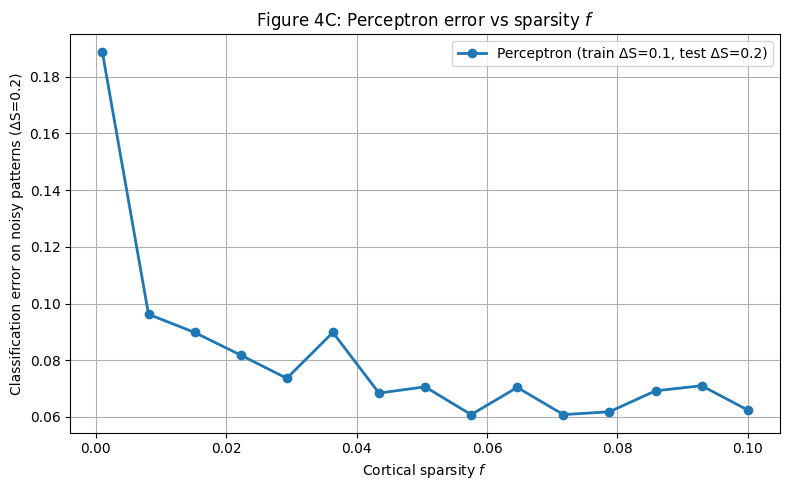

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1   # training noise
deltaS_test = 0.2    # testing noise
eta = 0.001
f_values = np.linspace(0.001, 0.1, 15)
final_errors = []

# Fixed labels and centers
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

for f in f_values:
    print(f"Training with f = {f:.3f}")

    # Random projection J
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # Use early-stopping training on ΔS = 0.1 noisy patterns
    W, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Compute threshold (reused for test too)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f) #same procedure inside the function train_perceptron_with_early_stopping

    # Test on ΔS = 0.2 noisy variants
    test_error = test_on_noisy_patterns(W, central_patterns, labels, J, T, f=f, deltaS_test=deltaS_test)
    final_errors.append(test_error)

# Plotting: error vs f
plt.figure(figsize=(8, 5))
plt.plot(f_values, final_errors, marker='o', lw=2, label='Perceptron (train ΔS=0.1, test ΔS=0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
plt.title("Figure 4C: Perceptron error vs sparsity $f$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# 3. Analysis of perceptron and Hebbian rule

deltaS_learn=0.1, eta=0,001, lenght(f_values)= 20, N_learn=10

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
N_learn = 10
f_values = np.linspace(0.001, 0.1, 20)

# Fixed central patterns and labels
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Containers for error values
perceptron_errors = []
hebbian_errors = []

for f in f_values:
    print(f"\n--- f = {f:.3f} ---")

    # New random projection J for each run
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # === Perceptron Training (ΔS = 0.1) ===
    W_p, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Threshold for both readouts (using ΔS = 0.1)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f) #same procedure inside the function train_perceptron_with_early_stopping

    # Test perceptron on ΔS = 0.2
    err_p = test_on_noisy_patterns(W_p, central_patterns, labels, J, T, f, deltaS_test)
    perceptron_errors.append(err_p)

    # Hebbian Training 
    W_h = np.zeros(N_C)
    for m in range(P):
        l = labels[m]
        noisy_samples, _, _ = generate_variations(
            central_patterns[m:m+1], [l], V=N_learn, flip_prob=deltaS_learn / 2
        )#For cluster m, generate V = N_learn noisy patterns from its central pattern using a fixed flip probability of ΔS_learn / 2
        cortical_samples, _ = compute_cortical_patterns(noisy_samples, J, T)
        for c in cortical_samples:
            c = c.astype(int)
            W_h += l * (c - f)

    # Test Hebbian on ΔS = 0.2
    err_h = test_on_noisy_patterns(W_h, central_patterns, labels, J, T, f, deltaS_test)
    hebbian_errors.append(err_h)



--- f = 0.001 ---
Stopped early at epoch 304

--- f = 0.006 ---
Stopped early at epoch 278

--- f = 0.011 ---
Stopped early at epoch 246

--- f = 0.017 ---
Stopped early at epoch 314

--- f = 0.022 ---
Stopped early at epoch 274

--- f = 0.027 ---
Stopped early at epoch 226

--- f = 0.032 ---
Stopped early at epoch 232

--- f = 0.037 ---
Stopped early at epoch 255

--- f = 0.043 ---
Stopped early at epoch 275

--- f = 0.048 ---
Stopped early at epoch 217

--- f = 0.053 ---
Stopped early at epoch 275

--- f = 0.058 ---
Stopped early at epoch 337

--- f = 0.064 ---
Stopped early at epoch 313

--- f = 0.069 ---
Stopped early at epoch 310

--- f = 0.074 ---
Stopped early at epoch 288

--- f = 0.079 ---
Stopped early at epoch 280

--- f = 0.084 ---
Stopped early at epoch 327

--- f = 0.090 ---
Stopped early at epoch 322

--- f = 0.095 ---
Stopped early at epoch 259

--- f = 0.100 ---
Stopped early at epoch 345


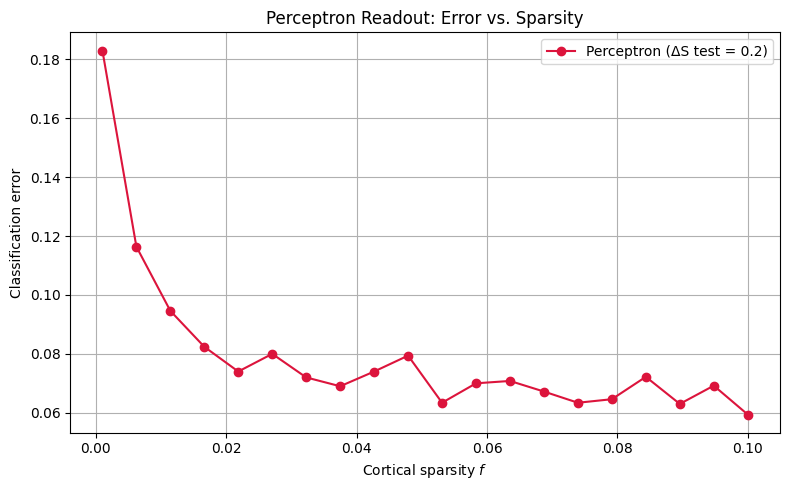

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, perceptron_errors, marker='o', color='crimson', label='Perceptron (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Perceptron Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


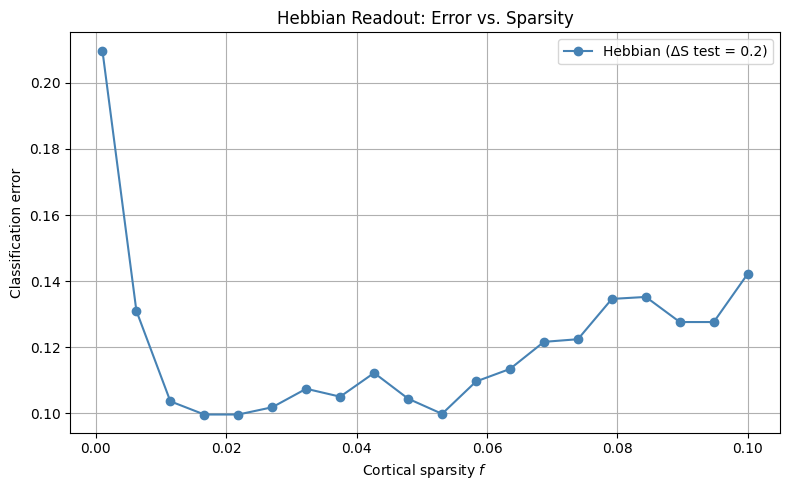

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, hebbian_errors, marker='o', color='steelblue', label='Hebbian (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Hebbian Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# 4. Simulation
deltaS_learn=0.1, eta=0,001, lenght(f_values)= 20, N_learn=100, V_test=10

# To be deleted
Same functions defined before

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

#Training of perceptron considering early stopping
def train_perceptron_with_early_stopping(
    central_patterns,          # shape: (P, N_S)
    labels,                    # shape: (P,)
    J,                         # shape: (N_C, N_S)
    f,                         # cortical sparsity
    deltaS_learn=0.1,          # learning noise
    eta=0.001,
    max_epochs=1000,
    patience=2                 # early stop after 2 blocks
):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    flip_prob = deltaS_learn / 2

    # Compute threshold T for cortical sparsity
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=100, flip_prob=flip_prob)
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Project central patterns to cortical space (for evaluation)
    central_cortical, _ = compute_cortical_patterns(central_patterns, J, T)
    central_cortical = central_cortical.astype(int)
    central_centered = central_cortical - f

    # Initialize weights
    W = np.random.normal(0, 1 / np.sqrt(N_C), size=N_C)

    block_size = 100
    block_errors = []
    converged = False

    for epoch in range(max_epochs):
        # One pattern per class (new noisy pattern each epoch)
        epoch_patterns = []
        epoch_targets = []

        for i in range(P):
            noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
            epoch_patterns.append(noisy_pattern[0])
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # Project to cortical space
        cortical_patterns, _ = compute_cortical_patterns(epoch_patterns, J, T)
        cortical_patterns = cortical_patterns.astype(int)

        # Update weights using perceptron rule
        for x, y in zip(cortical_patterns, epoch_targets):
            x_centered = x - f
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x

        # Evaluate on central patterns
        preds = np.sign(central_centered @ W)
        preds[preds == 0] = 1
        acc = np.mean(preds == labels)
        err = 1 - acc
        block_errors.append(err)

#ogni 100 epoche, controllo l'errore sulle central cortical patterns
        # Check convergence over 2 consecutive 100-epoch blocks
        if len(block_errors) >= 2 * block_size:
            block1 = np.mean(block_errors[-2*block_size : -block_size])
            block2 = np.mean(block_errors[-block_size:])
            if np.abs(block2 - block1) < 1e-4:
                print(f"Stopped early at epoch {epoch+1}")
                converged = True
                break

    return W, block_errors

# Testing on noisy patterns:
# This function tests the perceptron on noisy patterns generated from the central patterns.
# It computes the classification error based on the learned weights W.
def test_on_noisy_patterns(W, central_patterns, labels, J, T, f, deltaS_test=0.2, V_test=10):
    flip_prob_test = deltaS_test / 2

    # Generate noisy test patterns
    noisy_test, test_labels, _ = generate_variations(
        central_patterns, labels, V=V_test, flip_prob=flip_prob_test
    )

    # Project to cortical space
    cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
    cortical_test = cortical_test.astype(int)

    # Predict
    preds = np.sign((cortical_test - f) @ W)
    preds[preds == 0] = 1

    error = 1 - np.mean(preds == test_labels)
    return error

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
N_learn = 100
f_values = np.linspace(0.001, 0.1, 20)

# Fixed central patterns and labels
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Containers for error values
perceptron_errors = []
hebbian_errors = []

for i, f in enumerate(f_values):
    np.random.seed(42 + i)
    print(f"\n--- f = {f:.3f} ---")

    # New random projection J for each run
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # === Perceptron Training (ΔS = 0.1) ===
    W_p, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Threshold for both readouts (using ΔS = 0.1)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Test perceptron on ΔS = 0.2
    err_p = test_on_noisy_patterns(W_p, central_patterns, labels, J, T, f, deltaS_test)
    perceptron_errors.append(err_p)

    # === Hebbian Training ===
    W_h = np.zeros(N_C)
    for m in range(P):
        l = labels[m]
        noisy_samples, _, _ = generate_variations(
            central_patterns[m:m+1], [l], V=N_learn, flip_prob=deltaS_learn / 2
        )
        cortical_samples, _ = compute_cortical_patterns(noisy_samples, J, T)
        for c in cortical_samples:
            c = c.astype(int)
            W_h += l * (c - f)

    # Test Hebbian on ΔS = 0.2
    err_h = test_on_noisy_patterns(W_h, central_patterns, labels, J, T, f, deltaS_test)
    hebbian_errors.append(err_h)



--- f = 0.001 ---
Stopped early at epoch 397

--- f = 0.006 ---
Stopped early at epoch 296

--- f = 0.011 ---
Stopped early at epoch 291

--- f = 0.017 ---
Stopped early at epoch 319

--- f = 0.022 ---
Stopped early at epoch 237

--- f = 0.027 ---
Stopped early at epoch 240

--- f = 0.032 ---
Stopped early at epoch 347

--- f = 0.037 ---
Stopped early at epoch 312

--- f = 0.043 ---
Stopped early at epoch 238

--- f = 0.048 ---
Stopped early at epoch 440

--- f = 0.053 ---
Stopped early at epoch 230

--- f = 0.058 ---
Stopped early at epoch 427

--- f = 0.064 ---
Stopped early at epoch 380

--- f = 0.069 ---
Stopped early at epoch 270

--- f = 0.074 ---
Stopped early at epoch 287

--- f = 0.079 ---
Stopped early at epoch 459

--- f = 0.084 ---
Stopped early at epoch 390

--- f = 0.090 ---
Stopped early at epoch 266

--- f = 0.095 ---
Stopped early at epoch 309

--- f = 0.100 ---
Stopped early at epoch 407


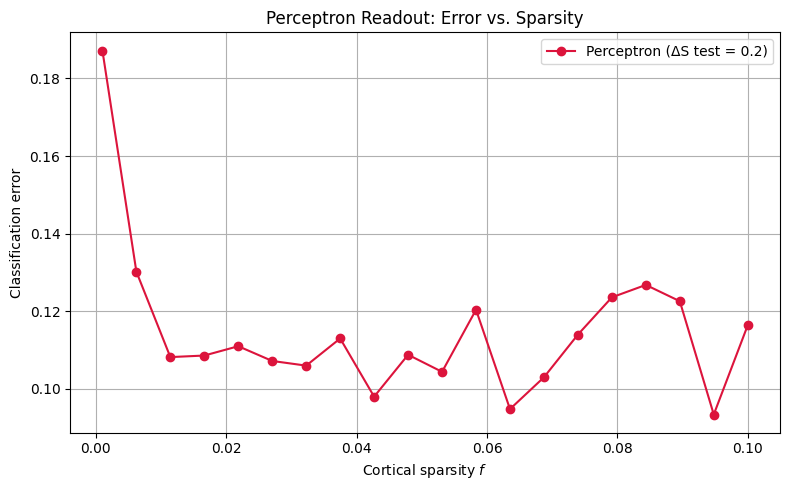

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, perceptron_errors, marker='o', color='crimson', label='Perceptron (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Perceptron Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

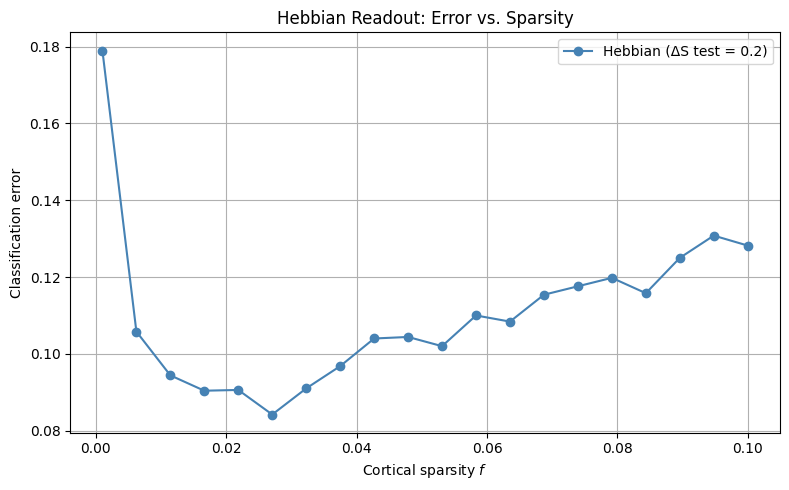

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, hebbian_errors, marker='o', color='steelblue', label='Hebbian (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Hebbian Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 5. Simulation averaging the error over multiple runs in the test
deltaS_learn=0.3

`test_on_noisy_patterns_avg` Function

Implements **statistical averaging** over multiple independent test evaluations to obtain more reliable and robust error estimates.
- **Single test runs**: Can be misleading due to random fluctuations in noise generation
- **Noise variability**: Different random noise realizations can produce different error rates
- **Statistical uncertainty**: Need reliable estimates for scientific conclusions



In [34]:
#averaging the error over multiple runs
# This function runs the test_on_noisy_patterns multiple times to average the error.
def test_on_noisy_patterns_avg(W, central_patterns, labels, J, T, f, deltaS_test=0.2, V_test=10, n_runs=5):
    errors = []
    for _ in range(n_runs):
        flip_prob_test = deltaS_test / 2
        noisy_test, test_labels, _ = generate_variations(
            central_patterns, labels, V=V_test, flip_prob=flip_prob_test
        )
        cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
        cortical_test = cortical_test.astype(int)
        preds = np.sign((cortical_test - f) @ W)
        preds[preds == 0] = 1
        error = 1 - np.mean(preds == test_labels)
        errors.append(error)
    return np.mean(errors)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.3
deltaS_test = 0.2
eta = 0.001
N_learn = 100
f_values = np.linspace(0.001, 0.1, 20)

# Fixed central patterns and labels
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# Containers for error values
perceptron_errors = []
hebbian_errors = []

for i, f in enumerate(f_values):
    np.random.seed(42 + i)
    print(f"\n--- f = {f:.3f} ---")

    # New random projection J for each run
    J = np.random.normal(0, 2/np.sqrt( N_S), size=(N_C, N_S))

    # === Perceptron Training (ΔS = 0.1) ===
    W_p, _ = train_perceptron_with_early_stopping(
        central_patterns, labels, J, f,
        deltaS_learn=deltaS_learn, eta=eta
    )

    # Threshold for both readouts (using ΔS = 0.1)
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Test perceptron on ΔS = 0.2
    err_p = test_on_noisy_patterns_avg(W_p, central_patterns, labels, J, T, f, deltaS_test, V_test=10, n_runs=5)
    perceptron_errors.append(err_p)

    # === Hebbian Training ===
    W_h = np.zeros(N_C)
    for m in range(P):
        l = labels[m]
        noisy_samples, _, _ = generate_variations(
            central_patterns[m:m+1], [l], V=N_learn, flip_prob=deltaS_learn / 2
        )
        cortical_samples, _ = compute_cortical_patterns(noisy_samples, J, T)
        for c in cortical_samples:
            c = c.astype(int)
            W_h += l * (c - f)

    # Test Hebbian on ΔS = 0.2
    err_h = test_on_noisy_patterns(W_h, central_patterns, labels, J, T, f, deltaS_test)
    hebbian_errors.append(err_h)



--- f = 0.001 ---
Stopped early at epoch 420

--- f = 0.006 ---
Stopped early at epoch 278

--- f = 0.011 ---
Stopped early at epoch 305

--- f = 0.017 ---
Stopped early at epoch 351

--- f = 0.022 ---
Stopped early at epoch 322

--- f = 0.027 ---
Stopped early at epoch 411

--- f = 0.032 ---
Stopped early at epoch 308

--- f = 0.037 ---
Stopped early at epoch 232

--- f = 0.043 ---
Stopped early at epoch 349

--- f = 0.048 ---
Stopped early at epoch 487

--- f = 0.053 ---
Stopped early at epoch 468

--- f = 0.058 ---
Stopped early at epoch 261

--- f = 0.064 ---
Stopped early at epoch 357

--- f = 0.069 ---
Stopped early at epoch 328

--- f = 0.074 ---
Stopped early at epoch 432

--- f = 0.079 ---
Stopped early at epoch 330

--- f = 0.084 ---
Stopped early at epoch 330

--- f = 0.090 ---
Stopped early at epoch 545

--- f = 0.095 ---
Stopped early at epoch 345

--- f = 0.100 ---
Stopped early at epoch 290


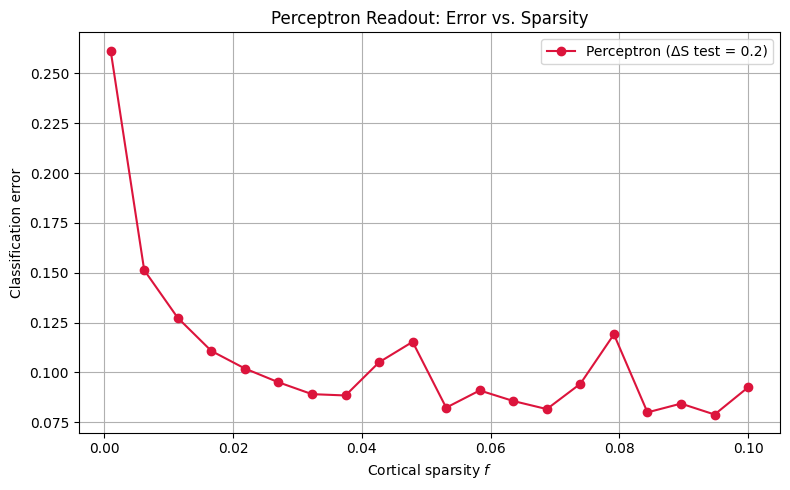

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, perceptron_errors, marker='o', color='crimson', label='Perceptron (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Perceptron Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

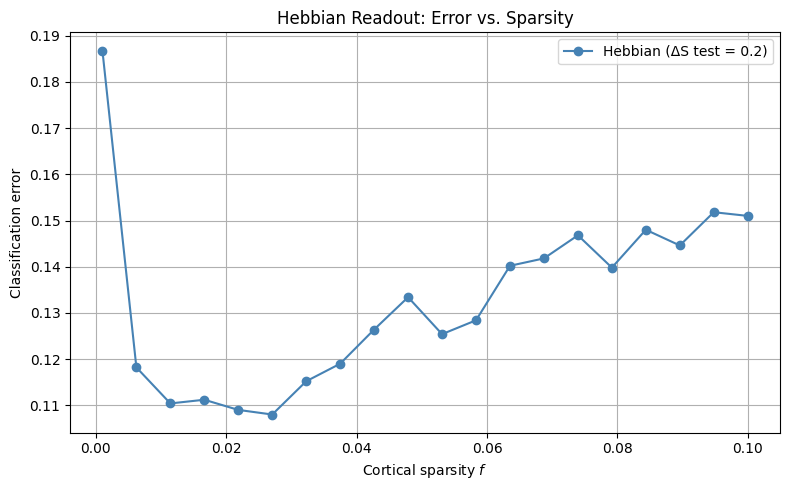

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(f_values, hebbian_errors, marker='o', color='steelblue', label='Hebbian (ΔS test = 0.2)')
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error")
plt.title("Hebbian Readout: Error vs. Sparsity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Multiple iterations

The setup uses a **nested statistical approach** with two levels of averaging:

1. **Inner Level**: Multiple runs per sparsity value (`n_runs = 10`)
2. **Outer Level**: Multiple complete iterations of the entire experiment (`n_iterations = 5`)

- **Key Parameters**

```python
n_iterations = 5   # Number of complete experimental repetitions
n_runs = 10        # Number of runs per sparsity value within each iteration
f_values = np.linspace(0.001, 0.1, 15)  # 15 sparsity levels to test
```

- **Individual Runs (Inner Loop)**
```python
for run in range(n_runs):  # 10 runs per f value
    # Different random projection J each run
    J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))
    
    # Train perceptron with early stopping
    W, _ = train_perceptron_with_early_stopping(...)
    
    # Test on noisy patterns
    test_error = test_on_noisy_patterns(...)
    errors.append(test_error)
```

- **Iteration Statistics (Middle Loop)**
```python
for f in f_values:
    errors = []  # Collect errors from all runs
    # ... run loop ...
    mean_errors.append(np.mean(errors))    # Mean across runs
    std_errors.append(np.std(errors))      # Standard deviation across runs
```

- **Cross-Iteration Analysis (Outer Loop)**
```python
for iteration in range(1, n_iterations + 1):
    # Generate new central patterns each iteration
    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)
    
    # ... complete experiment ...
    all_iterations.append(mean_errors)
```

**Purpose**: Account for variability in:
- Central pattern generation
- Label assignment
- Overall experimental conditions


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# Parametri
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
eta = 0.001
f_values = np.linspace(0.001, 0.2, 15)

n_iterations = 1   # quante volte ripetere l'intero esperimento
n_runs = 5        # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati di ogni iterazione
all_iterations = []

deltaS_test_array = [0.0, 0.1, 0.2, 0.3]

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iteration {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    # Dictionary: for each ΔS_test → list of mean errors across f
    mean_errors_per_delta = {d: [] for d in deltaS_test_array}
    std_errors_per_delta = {d: [] for d in deltaS_test_array}

    for deltaS_test in deltaS_test_array:
        print(f"  Testing with ΔS_test = {deltaS_test}")

        mean_errors = []
        std_errors = []

        for f in f_values:
            errors = []
            for run in range(n_runs):

                # Random projection
                J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))

                # Train
                W, _ = train_perceptron_with_early_stopping(
                    central_patterns, labels, J, f,
                    deltaS_learn=deltaS_learn, eta=eta
                )

                # Threshold
                noisy_train, _, _ = generate_variations(
                    central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
                )
                T = compute_global_threshold(central_patterns, noisy_train, J, f)

                # Test with the selected ΔS_test
                test_error = test_on_noisy_patterns(
                    W, central_patterns, labels, J, T,
                    f=f, deltaS_test=deltaS_test
                )
                errors.append(test_error)

            mean_errors.append(np.mean(errors))
            std_errors.append(np.std(errors))

        mean_errors_per_delta[deltaS_test] = mean_errors
        std_errors_per_delta[deltaS_test] = std_errors

    # ----- Plot for this iteration: multiple ΔS_test curves -----
    plt.figure(figsize=(8, 5))

    for deltaS_test in deltaS_test_array:
        plt.errorbar(
            f_values,
            mean_errors_per_delta[deltaS_test],
            yerr=std_errors_per_delta[deltaS_test],
            marker='o', lw=2, capsize=4,
            label=f"ΔS_test={deltaS_test}"
        )

    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns")
    plt.title(f"Iteration {iteration}: error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_multi_delta.png", dpi=300)
    plt.close()



=== Iteration 1/1 ===
  Testing with ΔS_test = 0.0
Stopped early at epoch 338
Stopped early at epoch 330
Stopped early at epoch 292
Stopped early at epoch 322
Stopped early at epoch 281
Stopped early at epoch 334
Stopped early at epoch 514
Stopped early at epoch 422
Stopped early at epoch 342
Stopped early at epoch 303
Stopped early at epoch 341
Stopped early at epoch 250
Stopped early at epoch 229
Stopped early at epoch 227
Stopped early at epoch 251
Stopped early at epoch 258
Stopped early at epoch 235
Stopped early at epoch 329
Stopped early at epoch 277
Stopped early at epoch 277
Stopped early at epoch 265
Stopped early at epoch 296
Stopped early at epoch 283
Stopped early at epoch 326
Stopped early at epoch 283
Stopped early at epoch 246
Stopped early at epoch 246
Stopped early at epoch 276
Stopped early at epoch 315
Stopped early at epoch 297
Stopped early at epoch 297
Stopped early at epoch 289
Stopped early at epoch 251
Stopped early at epoch 296
Stopped early at epoch 256
Sto

KeyboardInterrupt: 


=== Iterazione 1/5 ===
Stopped early at epoch 291
Stopped early at epoch 280
Stopped early at epoch 293
Stopped early at epoch 374
Stopped early at epoch 298
Stopped early at epoch 353
Stopped early at epoch 418
Stopped early at epoch 312
Stopped early at epoch 304
Stopped early at epoch 343
Stopped early at epoch 256
Stopped early at epoch 245
Stopped early at epoch 321
Stopped early at epoch 335
Stopped early at epoch 297
Stopped early at epoch 324
Stopped early at epoch 302
Stopped early at epoch 313
Stopped early at epoch 271
Stopped early at epoch 300
Stopped early at epoch 345
Stopped early at epoch 292
Stopped early at epoch 246
Stopped early at epoch 244
Stopped early at epoch 279
Stopped early at epoch 242
Stopped early at epoch 237
Stopped early at epoch 239
Stopped early at epoch 266
Stopped early at epoch 349
Stopped early at epoch 324
Stopped early at epoch 230
Stopped early at epoch 225
Stopped early at epoch 254
Stopped early at epoch 303
Stopped early at epoch 291
Stop

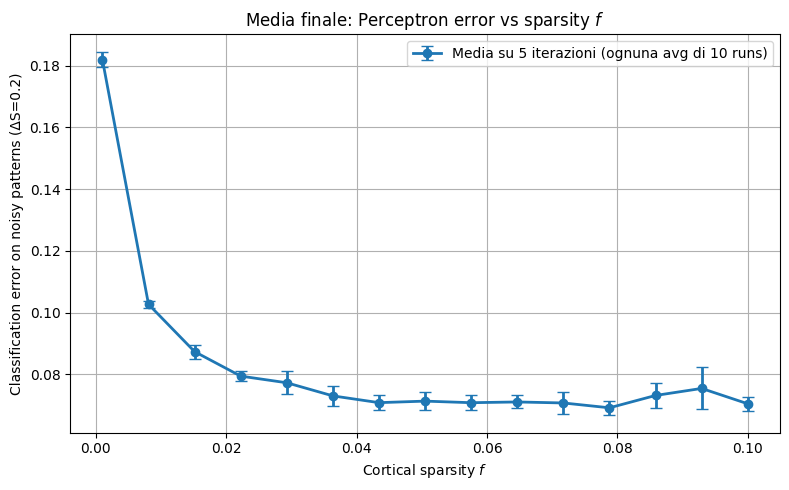

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# Parametri
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
f_values = np.linspace(0.001, 0.1, 15)

n_iterations = 5   # quante volte ripetere l'intero esperimento
n_runs = 10        # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati di ogni iterazione
all_iterations = []

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []
        for run in range(n_runs):
            # Random projection
            J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))

            # Train
            W, _ = train_perceptron_with_early_stopping(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # Threshold
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # Test
            test_error = test_on_noisy_patterns(
                W, central_patterns, labels, J, T, f=f, deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva i risultati di questa iterazione
    all_iterations.append(mean_errors)

    # Plot singola iterazione
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (avg di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}.png", dpi=300)
    plt.close()

# Final plot: average over all iterations
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)   # media tra iterazioni
final_std = np.std(all_iterations, axis=0)     # deviazione standard tra iterazioni

plt.figure(figsize=(8, 5))

plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
plt.title("Media finale: Perceptron error vs sparsity $f$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean.png", dpi=300)
plt.show()


# Enhancing Biological Plausibility


## Distribution of net input h

C:\Users\letiz\AppData\Local\Temp\ipykernel_28936\3233583883.py:49: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


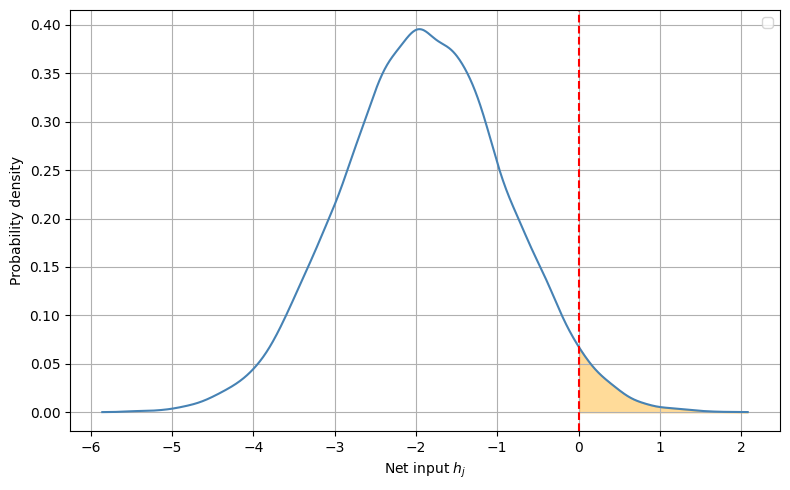

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

# Parameters
P = 1
V = 0
N_s = 9000
N_r = 20000

np.random.seed(42)

# Generate data
central_patterns = generate_central_patterns(P, N_s)
y = np.arange(P)
# Synaptic weights
J = np.random.normal(10/np.sqrt(N_s), 2/np.sqrt(N_s), size=(N_r, N_s))

# Compute h values
centered_input = central_patterns - 0.5
h = centered_input @ J.T  # shape: (num_patterns, N_r)
h_values = h.flatten()

# Compute threshold T for sparsity f
T = 0

# Estimate density using KDE
kde = gaussian_kde(h_values)
x_vals = np.linspace(np.min(h_values), np.max(h_values), 1000)
pdf_vals = kde(x_vals)

# Plot PDF curve
plt.figure(figsize=(8, 5))
plt.plot(x_vals, pdf_vals, color="steelblue")

# Add vertical line at threshold T
plt.axvline(T, color='red', linestyle='--')

# Shade area to the right of T (active neurons)
x_shade = x_vals[x_vals >= T]
y_shade = pdf_vals[x_vals >= T]
plt.fill_between(x_shade, y_shade, color='orange', alpha=0.4)

# Plot
plt.xlabel("Net input $h_j$")
plt.ylabel("Probability density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

a_S center 1 = 0.5075555555555555
a_S center 2 = 0.49755555555555553


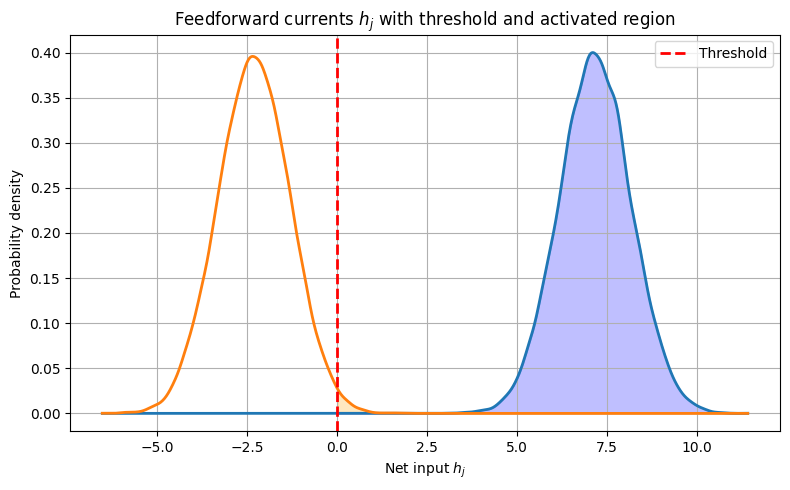

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# PARAMETERS
N_s = 9000
N_r = 20000
np.random.seed(42)

# ---- choose one a_S ----
aS = 0.5   # both centers have same mean activity

# ---- generate TWO different binary center patterns with SAME aS ----
center1 = (np.random.rand(N_s) < aS).astype(float)
center2 = (np.random.rand(N_s) < aS).astype(float)

print("a_S center 1 =", center1.mean())
print("a_S center 2 =", center2.mean())

# ---- synaptic weights J ----
J = np.random.normal(10/np.sqrt(N_s), 2/np.sqrt(N_s), size=(N_r, N_s))

# ---- compute feedforward currents ----
h1 = (center1 - 0.5) @ J.T
h2 = (center2 - 0.5) @ J.T

# ---- KDE densities ----
xmin = min(h1.min(), h2.min())
xmax = max(h1.max(), h2.max())
x_vals = np.linspace(xmin, xmax, 1000)

pdf1 = gaussian_kde(h1)(x_vals)
pdf2 = gaussian_kde(h2)(x_vals)

# ---- choose a threshold T ----
T = 0.0   # example threshold

# ---- plot ----
plt.figure(figsize=(8, 5))

# PDFs
plt.plot(x_vals, pdf1, lw=2)
plt.plot(x_vals, pdf2, lw=2)

# ---- vertical line at threshold ----
plt.axvline(T, color='red', linestyle='--', linewidth=2, label="Threshold")

# ---- shading area ABOVE threshold for center 1 ----
mask1 = x_vals >= T
plt.fill_between(x_vals[mask1], pdf1[mask1], color='blue', alpha=0.25)

# ---- shading area ABOVE threshold for center 2 ----
mask2 = x_vals >= T
plt.fill_between(x_vals[mask2], pdf2[mask2], color='orange', alpha=0.25)

# labels
plt.xlabel("Net input $h_j$")
plt.ylabel("Probability density")
plt.title("Feedforward currents $h_j$ with threshold and activated region")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


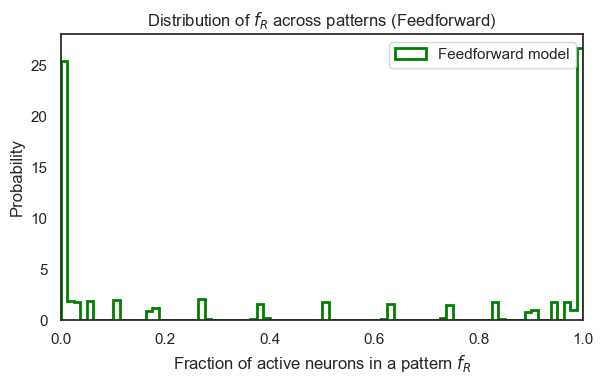

In [ ]:
# ----- Params -----
N_S = 1000         # sensory size
N_R = 20000        # representation size (large → precise f_R)
P   = 5000         # #patterns to sample histogram
f_S = 0.5         # sensory sparsity
beta = 10.0         # mean bias scale: m_J = beta/sqrt(N_S)
c     = 2       # weight std scale: sigma_J = c/sqrt(N_S)  (smaller → sharper 0/1 spikes)
#T = 0.0            # threshold for ReLU

rng = np.random.default_rng(1)

# ----- Sensory patterns and centering -----
S  = (rng.random((P, N_S)) < f_S).astype(float)     # {0,1}
X  = S - f_S                                         # centered inputs

# ----- Weights with nonzero mean -----

mJ    = beta / np.sqrt(N_S)
sigma = c    / np.sqrt(N_S)
J     = rng.normal(loc=mJ, scale=sigma, size=(N_R, N_S))
T = compute_global_threshold_central_only(S, J, 0.5)
# ----- Net inputs and per-pattern active fraction -----
H   = X @ J.T           # shape (P, N_R)
A = np.maximum(H - T, 0)
f_R = np.mean(A > 0, axis=1)

# ----- Histogram -----
plt.figure(figsize=(6.2, 4))
plt.hist(f_R, bins=80, density=True, histtype='step', linewidth=2, color='green', label='Feedforward model')
plt.xlabel(r'Fraction of active neurons in a pattern $f_R$')
plt.ylabel('Probability')
plt.title(r'Distribution of $f_R$ across patterns (Feedforward)')
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


## Perceptron classification

First I consider only central patterns

In [28]:
def train_perceptron_J(central_patterns, labels, f, epochs, eta):
    """
    Trains a perceptron on central cortical patterns only (Babadi-style).

    Parameters:
        central_patterns (ndarray): shape (P, N_r), cortical codes for central patterns
        labels (ndarray): shape (P,), target labels in {-1, +1}
        f (float): average activity (sparsity level)
        epochs (int): number of epochs to train
        eta (float): learning rate

    Returns:
        W (ndarray): learned weight vector (shape: N_r)
    """
    P, N_r = central_patterns.shape
    W = np.random.normal(0, 1 / np.sqrt(N_r), size=N_r)  # Init weights

    for epoch in range(epochs):
        errors = 0
        for mu in np.random.permutation(P):
            x_mu = central_patterns[mu] - f  # center the input
            y_mu = labels[mu]
            y_pred = np.sign(np.dot(x_mu, W))
            if y_pred == 0:
                y_pred = 1
            if y_mu * np.dot(x_mu, W) <= 0:  # misclassified
                W += eta * y_mu * x_mu
                errors += 1
        if errors == 0:
            break
    return W
def test_perceptron_J(test_patterns, labels, W, f):
    """
    Tests perceptron on test patterns (typically noisy cortical codes).

    Parameters:
        test_patterns (ndarray): shape (num_samples, N_r)
        labels (ndarray): true labels
        W (ndarray): trained weights
        f (float): sparsity level used for centering

    Returns:
        float: classification error
    """
    centered_test = test_patterns - f
    preds = np.sign(centered_test @ W)
    preds[preds == 0] = 1
    error = 1 - np.mean(preds == labels)
    return error
#Thresholding and classification
#how well the perceptron can distinguish between different stimulus patterns after projecting them to produce sparse binary cortical representations
#for a range of threshold values 𝑇

def run_threshold_J(all_patterns, labels, central_patterns, central_labels, N_r, N_s, epochs, eta, thresholds):
    J = np.random.normal(0, np.sqrt(2 / N_s), size=(N_r, N_s))
    fractions_active = []
    misclassification_rates = []

    for T in thresholds:
        A_R, _ = compute_cortical_patterns(all_patterns, J, T)  # all = central + noisy
        central_corticals, _ = compute_cortical_patterns(central_patterns, J, T)

        f_active = np.mean(A_R)  # overall sparsity
        fractions_active.append(f_active)

        # Train only on central patterns
        W = train_perceptron(central_corticals, central_labels, f_active, epochs, eta)

        # Test on all patterns
        error = test_perceptron(A_R, labels, W, f_active)
        misclassification_rates.append(error)

    return fractions_active, misclassification_rates

#plotting
def plot_smoothed_results_J(fractions_active, misclassification_rates, window_size=5):
    smoothed_error = np.convolve(misclassification_rates, np.ones(window_size)/window_size, mode='valid')
    plt.figure(figsize=(8, 5))
    plt.plot(fractions_active[:len(smoothed_error)], smoothed_error * 100, marker='o',lw=2)
    plt.xlabel('Sparsity $f$ (fraction active in cortical layer)')
    plt.ylabel('% Misclassification')
    plt.title('Perceptron classification vs. sparsity $f$')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [2]:
f_values = np.linspace(0.001, 0.3, 30)
epochs = 200
eta = 1e-3
N_S = 100         # sensory size
N_R = 2000        # representation size (large → precise f_R)
P   = 500         # #patterns to sample histogram
beta = 10.0         # mean bias scale: m_J = beta/sqrt(N_S)
c     = 2       # weight std scale: sigma_J = c/sqrt(N_S)  (smaller → sharper 0/1 spikes)

rng = np.random.default_rng(1)

# ----- Sensory patterns and centering -----
S  = (rng.random((P, N_S)) < f_S).astype(float)     # {0,1}                                         # centered inputs
labels = np.random.choice([-1, 1], size=P)
# ----- Weights with nonzero mean -----

mJ    = beta / np.sqrt(N_S)
sigma = c    / np.sqrt(N_S)

train_frac = 0.8
rng = np.random.default_rng(123)
perceptron_errors_train = []
perceptron_errors_test = []

for f in f_values:
    J     = rng.normal(loc=mJ, scale=sigma, size=(N_R, N_S))
    # compute global threshold using only centers
    T = compute_global_threshold_central_only(S, J, f)
    # project centers to cortical binary codes
    central_corticals, h = compute_cortical_patterns(S, J, T)

    # split indices into train / test (random, reproducible)
    P_total = central_corticals.shape[0]
    idx = np.arange(P_total)
    rng.shuffle(idx)
    n_train = int(np.round(train_frac * P_total))
    train_idx = idx[:n_train]
    test_idx  = idx[n_train:]

    X_train = central_corticals[train_idx]
    y_train = labels[train_idx]
    X_test  = central_corticals[test_idx]
    y_test  = labels[test_idx]

    # empirical sparsity used for centering (use training empirical f)
    f_train = float(np.mean(X_train))

    # train perceptron on training central patterns only
    W = train_perceptron_J(X_train, y_train, f, epochs=epochs, eta=eta)

    # evaluate on training and held-out test central patterns
    err_train = test_perceptron_J(X_train, y_train, W, f)
    err_test  = test_perceptron_J(X_test,  y_test,  W, f)

    perceptron_errors_train.append(err_train)
    perceptron_errors_test.append(err_test)

plot_smoothed_results_J(f_values, perceptron_errors, window_size=3)

NameError: name 'np' is not defined

Now I consider noisy patterns as done in the Babadi case

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

#
def train_perceptron_with_early_stopping(
    central_patterns,          # shape: (P, N_S)
    labels,                    # shape: (P,)
    J,                         # shape: (N_C, N_S)
    f,                        
    deltaS_learn=0.1,          # ΔS for training patterns
    eta=0.001,
    max_epochs=1000,
    patience=2                 # early stop after 2 blocks
):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    flip_prob = deltaS_learn / 2 #flip probability for training patterns

    # Compute threshold T for cortical sparsity
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=flip_prob) #depend on deltaS_learn
    T = compute_global_threshold(central_patterns, noisy_train, J, f)

    # Project central patterns to cortical space (for evaluation)
    central_cortical, _ = compute_cortical_patterns(central_patterns, J, T)
    central_cortical = central_cortical.astype(int)
    central_centered = central_cortical - f

    # Initialize weights
    W = np.random.normal(0, 1 / np.sqrt(N_C), size=N_C)

    block_size = 100
    block_errors = []
    converged = False

    for epoch in range(max_epochs): 
        epoch_patterns = []
        epoch_targets = []
        for i in range(P):
            noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
            epoch_patterns.append(noisy_pattern[0])
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # Project to cortical space
        cortical_patterns, _ = compute_cortical_patterns(epoch_patterns, J, T)
        cortical_patterns = cortical_patterns.astype(int)

        # Update weights using perceptron rule
        for x, y in zip(cortical_patterns, epoch_targets):
            x_centered = x - f
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x

        # Evaluate on central patterns
        preds = np.sign(central_centered @ W)
        preds[preds == 0] = 1
        acc = np.mean(preds == labels)
        err = 1 - acc
        block_errors.append(err)

        # Check convergence over 2 consecutive 100-epoch blocks
        #Ogni 100 epoche controlla se l’errore medio non migliora più. Se due blocchi consecutivi hanno errore simile ferma l’allenamento.
        if len(block_errors) >= 2 * block_size:
            block1 = np.mean(block_errors[-2*block_size : -block_size]) #
            block2 = np.mean(block_errors[-block_size:]) #Calcola la media degli errori sulle ultime 100 epoche.
            if np.abs(block2 - block1) < 1e-4: #perceptron stopped decreasing
                print(f"Stopped early at epoch {epoch+1}")
                converged = True
                break

    return W, block_errors

def test_on_noisy_patterns(W, central_patterns, labels, J, T, f, deltaS_test=0.2, V_test=5):
    flip_prob_test = deltaS_test / 2

    # Generate noisy test patterns
    noisy_test, test_labels, _ = generate_variations(
        central_patterns, labels, V=V_test, flip_prob=flip_prob_test
    )

    # Project to cortical space
    cortical_test, _ = compute_cortical_patterns(noisy_test, J, T)
    cortical_test = cortical_test.astype(int)

    # Predict
    preds = np.sign((cortical_test - f) @ W)
    preds[preds == 0] = 1

    error = 1 - np.mean(preds == test_labels)
    return error

Iterating over multiple iterations


=== Iterazione 1/1 ===
Stopped early at epoch 234
Stopped early at epoch 203
Stopped early at epoch 253
Stopped early at epoch 207
Stopped early at epoch 200
Stopped early at epoch 252
Stopped early at epoch 319
Stopped early at epoch 308
Stopped early at epoch 217
Stopped early at epoch 204
Stopped early at epoch 204
Stopped early at epoch 227
Stopped early at epoch 212
Stopped early at epoch 327
Stopped early at epoch 215
Stopped early at epoch 308
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 202
Stopped early at epoch 300
Stopped early at epoch 256
Stopped early at epoch 227
Stopped early at epoch 213
Stopped early at epoch 213
Stopped early at epoch 200
Stopped early at epoch 266
Stopped early at epoch 213
Stopped early at epoch 296
Stopped early at epoch 211
Stopped early at epoch 302
Stopped early at epoch 296
Stopped early at epoch 434
Stopped early at epoch 255
Stopped early at epoch 297
Stopped early at epoch 223
Stopped early at epoch 363
Stop

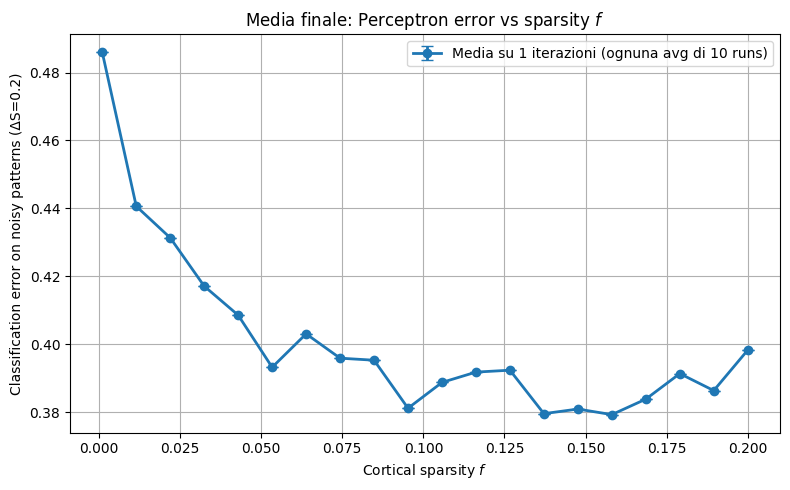

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# Parametri
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
f_values = np.linspace(0.001, 0.2, 20)
beta = 10.0         # mean bias scale: m_J = beta/sqrt(N_S)
c     = 2       # weight std scale: sigma_J = c/sqrt(N_S)  (smaller → sharper 0/1 spikes)

mJ    = beta / np.sqrt(N_S)
sigma = c    / np.sqrt(N_S)

n_iterations = 1   # quante volte ripetere l'intero esperimento
n_runs = 10        # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati di ogni iterazione
all_iterations = []

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []
        for run in range(n_runs):
            # Random projection
            J = np.random.normal(mJ, sigma, size=(N_C, N_S))
            # Train
            W, _ = train_perceptron_with_early_stopping(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # Threshold
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # Test
            test_error = test_on_noisy_patterns(
                W, central_patterns, labels, J, T, f=f, deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva i risultati di questa iterazione
    all_iterations.append(mean_errors)

    # Plot singola iterazione
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (avg di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_meanJ.png", dpi=300)
    plt.close()

# Final plot: average over all iterations
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)   # media tra iterazioni
final_std = np.std(all_iterations, axis=0)     # deviazione standard tra iterazioni

plt.figure(figsize=(8, 5))

plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
plt.title("Media finale: Perceptron error vs sparsity $f$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean__meanJ.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# Parametri
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
f_values = np.linspace(0.001, 0.1, 15)

n_iterations = 5   # quante volte ripetere l'intero esperimento
n_runs = 10        # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati di ogni iterazione
all_iterations = []

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []
        for run in range(n_runs):
            # Random projection
            J = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))

            # Train
            W, _ = train_perceptron_with_early_stopping(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # Threshold
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # Test
            test_error = test_on_noisy_patterns(
                W, central_patterns, labels, J, T, f=f, deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva i risultati di questa iterazione
    all_iterations.append(mean_errors)

    # Plot singola iterazione
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (avg di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}.png", dpi=300)
    plt.close()

# Final plot: average over all iterations
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)   # media tra iterazioni
final_std = np.std(all_iterations, axis=0)     # deviazione standard tra iterazioni

plt.figure(figsize=(8, 5))

plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
plt.title("Media finale: Perceptron error vs sparsity $f$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean.png", dpi=300)
plt.show()


**Considering a Relu activation function: $\phi(x)=max(x-T,0)$**

In [4]:
def phi(u, T):
    return np.maximum(u - T, 0.0)

def compute_ff_activation(patterns, J, T):
    """
    patterns : (P, N_S)
    J        : (N_R, N_S)
    T        : scalar threshold

    Returns:
        A : (P, N_R) rectified activations
        H : (P, N_R) pre-activation currents
    """
    H = (patterns - 0.5) @ J.T
    A = phi(H, T)
    return A, H

def compute_global_threshold_relu(central_patterns, noisy_patterns, J, f):
    """
    T : threshold such that approximately fraction f of all neurons
        (across central + noisy patterns) are active: H > T.
    """

    h_all = []

    # ---- 1. Currents for central patterns ----
    # central patterns
    for center in central_patterns:
        h_center = J @ (center - 0.5)
        h_all.append(h_center)

    # noisy patterns
    for noisy in noisy_patterns:
        h_noisy = J @ (noisy - 0.5)
        h_all.append(h_noisy)
    # ---- 3. Combine all currents ----
    h_all = np.concatenate(h_all)

    # ---- 4. OLD behavior: threshold is (1 - f)-quantile of all currents ----
    T = np.quantile(h_all, 1 - f)        # same as old percentile rule
    return T



In [22]:

# Perceptron training with ReLU activation function(with correct centering)
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

#
def train_perceptron_with_early_stopping_relu(
    central_patterns,          # shape: (P, N_S)
    labels,                    # shape: (P,)
    J,                         # shape: (N_C, N_S)
    f,                        
    deltaS_learn=0.1,          # ΔS for training patterns
    eta=0.001,
    max_epochs=1000,
    patience=2                 # early stop after 2 blocks
):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    flip_prob = deltaS_learn / 2 #flip probability for training patterns

    # Compute threshold T for cortical sparsity
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=flip_prob) #depend on deltaS_learn
    T = compute_global_threshold_relu(central_patterns, noisy_train, J, f)

    # Project central patterns to cortical space (for evaluation)
    central_cortical, _ = compute_ff_activation(central_patterns, J, T)
    central_cortical = central_cortical
    central_centered = central_cortical - f
    mean_activity = np.mean(central_cortical, axis=0)   # (N_R,)
    central_centered = central_cortical - mean_activity
    # Initialize weights
    W = np.random.normal(0, 1 / np.sqrt(N_C), size=N_C)

    block_size = 100
    block_errors = []
    converged = False

    for epoch in range(max_epochs): 
        epoch_patterns = []
        epoch_targets = []
        for i in range(P):
            noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
            epoch_patterns.append(noisy_pattern[0])
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # Project to cortical space
        cortical_patterns, _ = compute_ff_activation(epoch_patterns, J, T)
        cortical_patterns = cortical_patterns

        # Update weights using perceptron rule
        for x, y in zip(cortical_patterns, epoch_targets):
            x_centered = x - mean_activity
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x_centered

        # Evaluate on central patterns
        preds = np.sign(central_centered @ W)
        preds[preds == 0] = 1
        acc = np.mean(preds == labels)
        err = 1 - acc
        block_errors.append(err)

        # Check convergence over 2 consecutive 100-epoch blocks
        #Ogni 100 epoche controlla se l’errore medio non migliora più. Se due blocchi consecutivi hanno errore simile ferma l’allenamento.
        if len(block_errors) >= 2 * block_size:
            block1 = np.mean(block_errors[-2*block_size : -block_size]) #
            block2 = np.mean(block_errors[-block_size:]) #Calcola la media degli errori sulle ultime 100 epoche.
            if np.abs(block2 - block1) < 1e-4: #perceptron stopped decreasing
                print(f"Stopped early at epoch {epoch+1}")
                converged = True
                break

    return W, T, mean_activity, block_errors

#testing function
def test_on_noisy_patterns_relu(W, central_patterns, labels, J, T, mean_activity,
                                deltaS_test=0.2, V_test=5):
    flip_prob_test = deltaS_test / 2

    noisy_test, test_labels, _ = generate_variations(
        central_patterns, labels, V=V_test, flip_prob=flip_prob_test
    )

    A_test, _ = compute_ff_activation(noisy_test, J, T)
    A_test_centered = A_test - mean_activity

    preds = np.sign(A_test_centered @ W)
    preds[preds == 0] = 1

    error = 1 - np.mean(preds == test_labels)
    return error


=== Iterazione 1/1 ===
Stopped early at epoch 292
Stopped early at epoch 223
Stopped early at epoch 254
Stopped early at epoch 292
Stopped early at epoch 263
Stopped early at epoch 231
Stopped early at epoch 278
Stopped early at epoch 261
Stopped early at epoch 326
Stopped early at epoch 321
Stopped early at epoch 298
Stopped early at epoch 385
Stopped early at epoch 476
Stopped early at epoch 464
Stopped early at epoch 337
Stopped early at epoch 294
Stopped early at epoch 340
Stopped early at epoch 304
Stopped early at epoch 277
Stopped early at epoch 385
Stopped early at epoch 360
Stopped early at epoch 363
Stopped early at epoch 505
Stopped early at epoch 700
Stopped early at epoch 525
Stopped early at epoch 344
Stopped early at epoch 365
Stopped early at epoch 505
Stopped early at epoch 423
Stopped early at epoch 366
Stopped early at epoch 464
Stopped early at epoch 332
Stopped early at epoch 338
Stopped early at epoch 477
Stopped early at epoch 314
Stopped early at epoch 421
Stop

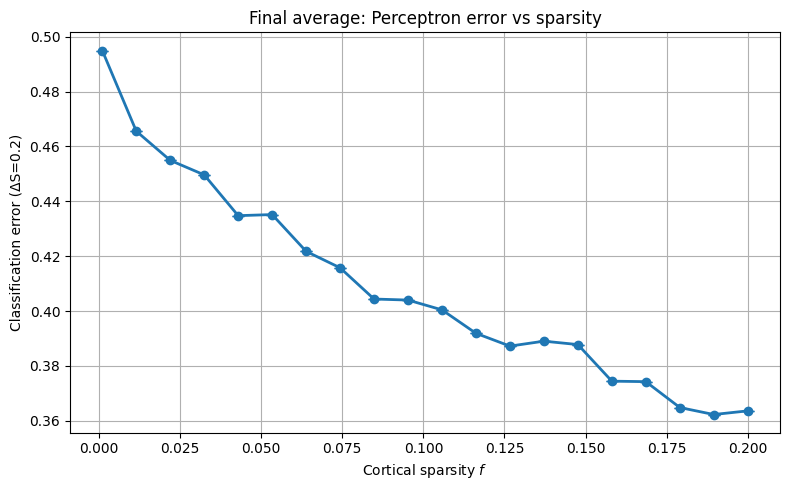

In [23]:
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

P = 900
N_S = 1000
N_C = 10000

deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001

f_values = np.linspace(0.001, 0.2, 20)

beta = 10.0
c     = 2      

mJ    = beta / np.sqrt(N_S)
sigma = c    / np.sqrt(N_S)

n_iterations = 1
n_runs = 10

all_iterations = []

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []
        for run in range(n_runs):

            # Random projection matrix J
            J = np.random.normal(mJ, sigma, size=(N_C, N_S))

            # ---------- TRAIN ----------
            W, T, mean_activity, _ = train_perceptron_with_early_stopping_relu(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # ---------- TEST ----------
            test_error = test_on_noisy_patterns_relu(
                W, central_patterns, labels,
                J, T, mean_activity,
                deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    all_iterations.append(mean_errors)

    # plot for this iteration
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors,
        marker='o', lw=2, capsize=4
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Error vs sparsity $f$")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_relu.png", dpi=300)
    plt.close()


# ============================================================
# 5. Final average across iterations
# ============================================================

all_iterations = np.array(all_iterations)
final_mean = all_iterations.mean(axis=0)
final_std  = all_iterations.std(axis=0)

plt.figure(figsize=(8, 5))
plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4
)
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error (ΔS=0.2)")
plt.title("Final average: Perceptron error vs sparsity")
plt.grid(True)
plt.tight_layout()
plt.savefig("plot_final_relu.png", dpi=300)
plt.show()


=== Iterazione 1/1 ===
Stopped early at epoch 297
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 200
Stopped early at epoch 369
Stopped early at epoch 410
Stopped early at epoch 420
Stopped early at epoch 426
Stopped early at epoch 528
Stopped early at epoch 387
Stopped early at epoch 466
Stopped early at epoch 505
Stopped early at epoch 314
Stopped early at epoch 457
Stopped early at epoch 274
Stopped early at epoch 519
Stopped early at epoch 657
Stopped early at epoch 462
Stopped early at epoch 275
Stopped early at epoch 237
Stopped early at epoch 346
Stopped early at epoch 240
Stopped early at epoch 390
Stopped early at epoch 280
Stopped early at epoch 401
Stopped early at epoch 411
Stopped early at epoch 534
Stopped early at epoch 807
Stopped early at epoch 480
Stopped early at epoch 739
Stop

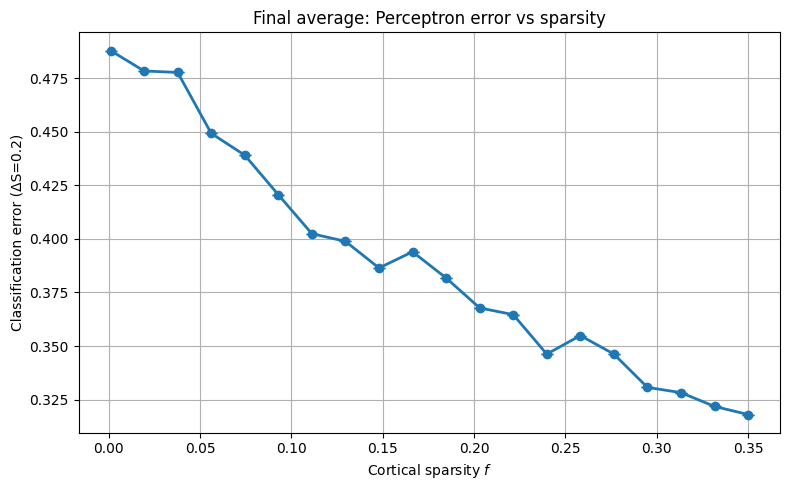

In [30]:
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

P = 90
N_S = 100
N_C = 1000

deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001

f_values = np.linspace(0.001, 0.35, 20)

beta = 10.0
c     = 2      

mJ    = beta / np.sqrt(N_S)
sigma = c    / np.sqrt(N_S)

n_iterations = 1
n_runs = 10

all_iterations = []

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []
        for run in range(n_runs):

            # Random projection matrix J
            J_eff = np.random.normal(mJ, sigma, size=(N_C, N_S))
            J = J_eff/np.sqrt(N_S)

            # ---------- TRAIN ----------
            W, T, mean_activity, _ = train_perceptron_with_early_stopping_relu(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # ---------- TEST ----------
            test_error = test_on_noisy_patterns_relu(
                W, central_patterns, labels,
                J, T, mean_activity,
                deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    all_iterations.append(mean_errors)

    # plot for this iteration
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors,
        marker='o', lw=2, capsize=4
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Error vs sparsity $f$")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_relu.png", dpi=300)
    plt.close()


# ============================================================
# 5. Final average across iterations
# ============================================================

all_iterations = np.array(all_iterations)
final_mean = all_iterations.mean(axis=0)
final_std  = all_iterations.std(axis=0)

plt.figure(figsize=(8, 5))
plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4
)
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error (ΔS=0.2)")
plt.title("Final average: Perceptron error vs sparsity")
plt.grid(True)
plt.tight_layout()
plt.savefig("plot_final_relu.png", dpi=300)
plt.show()

# Considering the effect of Q

In [24]:
import json
import os

CHECKPOINT_FILE = "checkpoint.json"

In [25]:
def save_checkpoint(iter_idx, f_idx, run_idx):
    with open(CHECKPOINT_FILE, "w") as f:
        json.dump({
            "iteration": iter_idx,
            "f_index": f_idx,
            "run_index": run_idx
        }, f)

def load_checkpoint():
    if not os.path.exists(CHECKPOINT_FILE):
        return 0, 0, 0     # start from scratch
    with open(CHECKPOINT_FILE, "r") as f:
        data = json.load(f)
    return data["iteration"], data["f_index"], data["run_index"]



=== Iterazione 1/1 ===
Stopped early at epoch 389
Stopped early at epoch 342
Stopped early at epoch 282
Stopped early at epoch 360
Stopped early at epoch 394
Stopped early at epoch 346
Stopped early at epoch 310
Stopped early at epoch 320
Stopped early at epoch 337
Stopped early at epoch 415
Stopped early at epoch 308
Stopped early at epoch 319
Stopped early at epoch 298
Stopped early at epoch 255
Stopped early at epoch 294
Stopped early at epoch 251
Stopped early at epoch 272
Stopped early at epoch 328
Stopped early at epoch 338
Stopped early at epoch 253
Stopped early at epoch 241
Stopped early at epoch 232
Stopped early at epoch 275
Stopped early at epoch 235
Stopped early at epoch 277
Stopped early at epoch 237
Stopped early at epoch 251
Stopped early at epoch 320
Stopped early at epoch 245
Stopped early at epoch 230
Stopped early at epoch 265
Stopped early at epoch 229
Stopped early at epoch 271
Stopped early at epoch 315
Stopped early at epoch 256
Stopped early at epoch 223
Stop

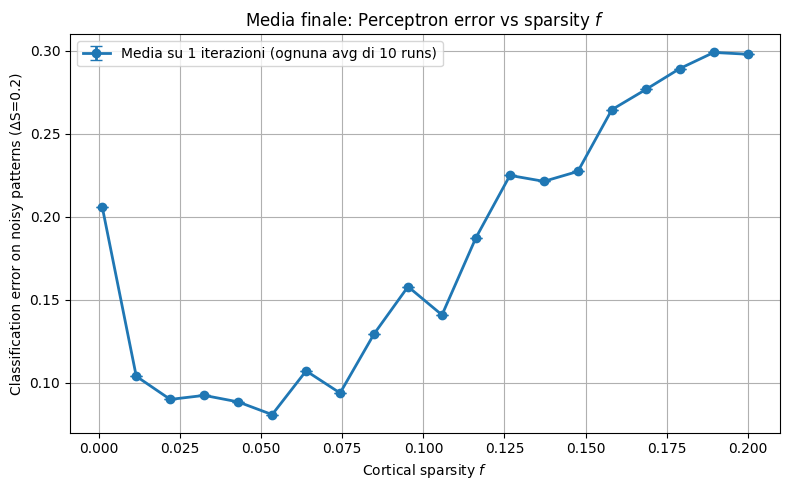

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# Parametri
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001
f_values = np.linspace(0.001, 0.2, 20)
beta = 10.0         # mean bias scale: m_J = beta/sqrt(N_S)
c     = 2       # weight std scale: sigma_J = c/sqrt(N_S)  (smaller → sharper 0/1 spikes)
q=0.1               # connection probability
mJ    = beta / np.sqrt(N_S)
sigma = c    / np.sqrt(N_S)

n_iterations = 1   # quante volte ripetere l'intero esperimento
n_runs = 10        # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati di ogni iterazione
all_iterations = []

for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []
        for run in range(n_runs):
            # Random projection
            Q = (np.random.rand(N_C, N_S) < q).astype(float)

            J_dense = np.random.normal(mJ, sigma, size=(N_C, N_S))
            J= J_dense * Q  # apply sparsity
            # Train
            W, _ = train_perceptron_with_early_stopping(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # Threshold
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # Test
            test_error = test_on_noisy_patterns(
                W, central_patterns, labels, J, T, f=f, deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva i risultati di questa iterazione
    all_iterations.append(mean_errors)

    # Plot singola iterazione
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (avg di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_meanJ_Q.png", dpi=300)
    plt.close()

# Final plot: average over all iterations
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)   # media tra iterazioni
final_std = np.std(all_iterations, axis=0)     # deviazione standard tra iterazioni

plt.figure(figsize=(8, 5))

plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
plt.title("Media finale: Perceptron error vs sparsity $f$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean__meanJ_Q.png", dpi=300)
plt.show()

In [30]:
def train_perceptron_with_early_stopping(central_patterns, labels, J, f, deltaS_learn, eta, max_epochs=50, tol=1e-3):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    
    # Inizializzazione pesi (se non forniti esternamente, qui assumiamo partano da 0 o random piccolo)
    # Nota: Nel tuo script principale passi J, ma W viene appreso qui.
    # Solitamente per il Perceptron i pesi W sono N_C (corticali) -> 1 (output)
    W = np.zeros(N_C) 
    
    best_W = W.copy()
    min_error = float('inf')
    no_improve_count = 0
    patience = 5  # Early stopping patience

    for epoch in range(max_epochs):
        
        # === CORREZIONE QUI ===
        # Devi inizializzare queste liste all'inizio di ogni epoca
        epoch_patterns = []
        epoch_targets = []
        # ======================

        # Generazione varianti rumorose per l'addestramento (Online learning)
        for i in range(P):
            # Genera 1 variante rumorosa per il pattern i-esimo
            noisy_pattern, _, _ = generate_variations(
                central_patterns[i:i+1], 
                labels[i:i+1], 
                V=1, 
                flip_prob=deltaS_learn/2
            )
            
            # Proietta pattern corticale (h)
            # h = Theta( J * xi - threshold ) ... qui assumiamo una versione semplificata o k-winner-take-all
            # Se usi k-WTA (fisso f):
            
            xi = noisy_pattern[0]
            current = np.dot(J, xi)
            
            # Calcolo soglia per sparsità f
            # (Se hai una funzione ottimizzata, usala, altrimenti calcolo al volo)
            # K = int(f * N_C)
            # threshold_val = np.sort(current)[-K]
            # h = (current >= threshold_val).astype(float)
            
            # NOTA: Per semplicità, qui assumo tu abbia una logica di proiezione. 
            # Se la proiezione avviene FUORI, adatta di conseguenza. 
            # In genere però si salvano i pattern di input o i pattern proiettati.
            
            epoch_patterns.append(xi) # O append(h) se proietti subito
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # ... (Qui segue la logica di aggiornamento dei pesi W) ...
        # Esempio classico Perceptron update:
        # errors = 0
        # for i in range(P):
        #    h = proietta(epoch_patterns[i], J) ...
        #    y_pred = np.sign(np.dot(W, h))
        #    if y_pred != epoch_targets[i]:
        #        W += eta * epoch_targets[i] * h
        #        errors += 1
        
        # Early stopping logic...
        
    return W, [] # Ritorna W e storia errori

In [31]:
#putting together functions from babadi, non zero mean J and Q
import numpy as np
import matplotlib.pyplot as plt

# Assumo che questi import funzionino nel tuo ambiente locale
from data_generation2 import generate_central_patterns
from generate_var import generate_variations
# Assumo che queste funzioni siano definite o importate altrove nel tuo codice
# (Se sono in un altro file, aggiungi i relativi import)
# from perceptron_functions import train_perceptron_with_early_stopping, compute_global_threshold, test_on_noisy_patterns

# ==========================================
# 1. PARAMETRI GLOBALI
# ==========================================
P = 1000
N_S = 1000
N_C = 10000
deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001

# Range unificato per asse X
f_values = np.linspace(0.001, 0.2, 20) 

# Parametri specifici per Mean Bias e Sparse
beta = 10.0      # mean bias scale
c = 2            # weight std scale
q = 0.1          # connection probability

mJ = beta / np.sqrt(N_S)
sigma = c / np.sqrt(N_S)

# Setup simulazione
n_iterations = 1  # Solo 1 iterazione "macro" come richiesto
n_runs = 10       # Run per smoothing

# Dizionari per salvare i risultati delle 3 curve
results = {
    "Standard": {"means": [], "stds": [], "color": "blue"},
    "MeanBias": {"means": [], "stds": [], "color": "orange"},
    "SparseMean": {"means": [], "stds": [], "color": "green"}
}

print(f"=== Inizio Simulazione (Iterazione Unica, {n_runs} runs per punto) ===")

# Generazione dati (fissa per l'esperimento o rigenerata, qui la teniamo fuori dal loop f per coerenza)
labels = np.random.choice([-1, 1], size=P)
central_patterns = generate_central_patterns(P, N_S)

# ==========================================
# 2. LOOP SU SPARSITY f
# ==========================================
for idx, f in enumerate(f_values):
    print(f"Processing f = {f:.3f} ({idx+1}/{len(f_values)})")
    
    # Buffer temporanei per gli errori delle 3 varianti
    err_std = []
    err_bias = []
    err_sparse = []

    for run in range(n_runs):
        # -------------------------------------------------
        # CASE 1: Standard Random Projection ( Babadi)
        # -------------------------------------------------
        J1 = np.random.normal(0, 2/np.sqrt(N_S), size=(N_C, N_S))
        
        W1, _ = train_perceptron_with_early_stopping(
            central_patterns, labels, J1, f, deltaS_learn=deltaS_learn, eta=eta
        )
        
        noisy_train1, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
        T1 = compute_global_threshold(central_patterns, noisy_train1, J1, f)
        
        test_err1 = test_on_noisy_patterns(W1, central_patterns, labels, J1, T1, f=f, deltaS_test=deltaS_test)
        err_std.append(test_err1)

        # -------------------------------------------------
        # CASE 2: Mean Bias Projection
        # -------------------------------------------------
        J2 = np.random.normal(mJ, sigma, size=(N_C, N_S))
        
        W2, _ = train_perceptron_with_early_stopping(
            central_patterns, labels, J2, f, deltaS_learn=deltaS_learn, eta=eta
        )
        
        noisy_train2, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
        T2 = compute_global_threshold(central_patterns, noisy_train2, J2, f)
        
        test_err2 = test_on_noisy_patterns(W2, central_patterns, labels, J2, T2, f=f, deltaS_test=deltaS_test)
        err_bias.append(test_err2)

        # -------------------------------------------------
        # CASE 3: Sparse + Mean Bias Projection
        # -------------------------------------------------
        Q = (np.random.rand(N_C, N_S) < q).astype(float)
        J_dense = np.random.normal(mJ, sigma, size=(N_C, N_S))
        J3 = J_dense * Q
        
        W3, _ = train_perceptron_with_early_stopping(
            central_patterns, labels, J3, f, deltaS_learn=deltaS_learn, eta=eta
        )
        
        noisy_train3, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=deltaS_learn / 2)
        T3 = compute_global_threshold(central_patterns, noisy_train3, J3, f)
        
        test_err3 = test_on_noisy_patterns(W3, central_patterns, labels, J3, T3, f=f, deltaS_test=deltaS_test)
        err_sparse.append(test_err3)

    # Calcolo media e deviazione standard per questo valore di f
    results["Standard"]["means"].append(np.mean(err_std))
    results["Standard"]["stds"].append(np.std(err_std))
    
    results["MeanBias"]["means"].append(np.mean(err_bias))
    results["MeanBias"]["stds"].append(np.std(err_bias))
    
    results["SparseMean"]["means"].append(np.mean(err_sparse))
    results["SparseMean"]["stds"].append(np.std(err_sparse))

# ==========================================
# 3. PLOTTING UNIFICATO
# ==========================================
plt.figure(figsize=(10, 6))

# Funzione helper per plottare linea + sfumatura
def plot_with_shade(x, res_dict, label_name):
    means = np.array(res_dict["means"])
    stds = np.array(res_dict["stds"])
    color = res_dict["color"]
    
    # Plot linea media
    plt.plot(x, means, marker='o', lw=2, color=color, label=label_name)
    
    # Plot area sfumata (Media ± Std)
    plt.fill_between(x, means - stds, means + stds, color=color, alpha=0.2)

# Traccia le 3 curve
plot_with_shade(f_values, results["Standard"], "Standard Random (Babadi))")
plot_with_shade(f_values, results["MeanBias"], f"Mean Bias (beta={beta})")
plot_with_shade(f_values, results["SparseMean"], f"Sparse Conn. (q={q}) + Bias")

# Formattazione Plot
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns ($\Delta S=0.2$)")
plt.title("Comparison of Projection Strategies: Error vs Sparsity $f$")
plt.grid(True, which="both", ls="-", alpha=0.6)
plt.legend(loc="best")

# Uniformare assi (opzionale, ma fill_between può sbordare leggermente)
plt.xlim(f_values[0], f_values[-1])
# Se vuoi forzare l'asse Y da 0 a 1 (o un max sensato):
# plt.ylim(0.0, 0.6) 

plt.tight_layout()
plt.savefig("comparison_plot_shaded.png", dpi=300)
plt.show()

<>:143: SyntaxWarning: invalid escape sequence '\D'
<>:143: SyntaxWarning: invalid escape sequence '\D'
C:\Users\letiz\AppData\Local\Temp\ipykernel_14192\2026974004.py:143: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("Classification error on noisy patterns ($\Delta S=0.2$)")


=== Inizio Simulazione (Iterazione Unica, 10 runs per punto) ===
Processing f = 0.001 (1/20)
Processing f = 0.011 (2/20)
Processing f = 0.022 (3/20)
Processing f = 0.032 (4/20)
Processing f = 0.043 (5/20)
Processing f = 0.053 (6/20)
Processing f = 0.064 (7/20)
Processing f = 0.074 (8/20)


KeyboardInterrupt: 

As done for the previous case, I consider now a **ReLU activation function** considering the effect of Q


=== Iterazione 1/1 ===
Stopped early at epoch 540
Stopped early at epoch 488
Stopped early at epoch 619
Stopped early at epoch 406
Stopped early at epoch 391
Stopped early at epoch 352
Stopped early at epoch 457
Stopped early at epoch 340
Stopped early at epoch 359
Stopped early at epoch 634
Stopped early at epoch 798
Stopped early at epoch 633
Stopped early at epoch 806
Stopped early at epoch 511
Stopped early at epoch 819
Stopped early at epoch 604
Stopped early at epoch 593
Stopped early at epoch 875
Stopped early at epoch 604
Stopped early at epoch 903
Stopped early at epoch 543
Stopped early at epoch 539
Stopped early at epoch 575
Stopped early at epoch 564
Stopped early at epoch 620
Stopped early at epoch 519
Stopped early at epoch 493
Stopped early at epoch 531
Stopped early at epoch 521
Stopped early at epoch 480
Stopped early at epoch 387
Stopped early at epoch 525
Stopped early at epoch 418
Stopped early at epoch 511
Stopped early at epoch 577
Stopped early at epoch 414
Stop

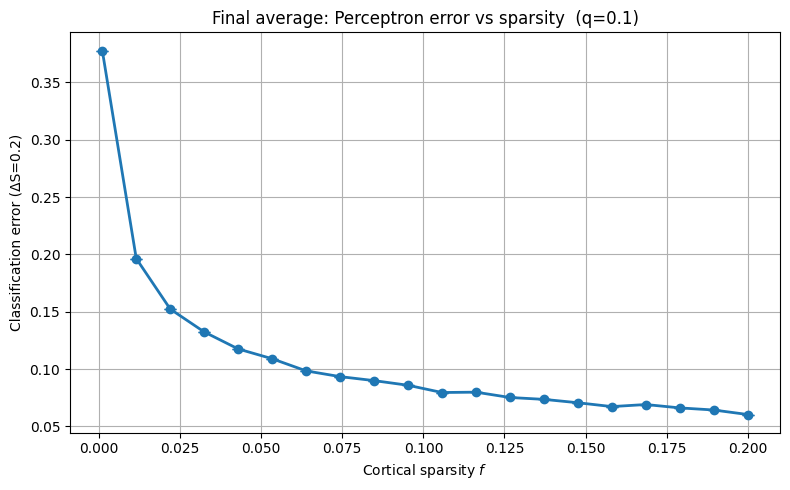

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

# ============================================================
# PARAMETERS
# ============================================================

P = 1000
N_S = 1000
N_C = 10000

deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001

f_values = np.linspace(0.001, 0.2, 20)

beta = 10.0             # mean of synapses
c     = 2               # std of synapses
q     = 0.1             # connection probability

mJ    = beta / np.sqrt(N_S)     # mean
sigma = c    / np.sqrt(N_S)     # std

n_iterations = 1
n_runs = 10

# ============================================================
# STORAGE
# ============================================================

all_iterations = []

# ============================================================
# MAIN LOOP
# ============================================================

for iteration in range(1, n_iterations + 1):

    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f in f_values:
        errors = []

        for run in range(n_runs):

            # --------------------------------------------------------
            # Q–MASKED RANDOM PROJECTION  (sparse connectivity)
            # --------------------------------------------------------
            Qmask = (np.random.rand(N_C, N_S) < q).astype(float)
            J_dense = np.random.normal(mJ, sigma, size=(N_C, N_S))
            J = J_dense * Qmask

            # --------------------------------------------------------
            # TRAINING (returns W, T, mean_activity)
            # --------------------------------------------------------
            W, T, mean_activity, _ = train_perceptron_with_early_stopping_relu(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # --------------------------------------------------------
            # TESTING
            # --------------------------------------------------------
            test_error = test_on_noisy_patterns_relu(
                W, central_patterns, labels,
                J, T, mean_activity,
                deltaS_test=deltaS_test
            )
            errors.append(test_error)

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    all_iterations.append(mean_errors)

    # --------------------------------------------------------
    # PLOT FOR THIS ITERATION
    # --------------------------------------------------------
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors,
        marker='o', lw=2, capsize=4
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$  (q={q})")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_q_{q}.png", dpi=300)
    plt.close()


# ============================================================
# FINAL AVERAGE ACROSS ITERATIONS
# ============================================================

all_iterations = np.array(all_iterations)
final_mean = all_iterations.mean(axis=0)
final_std  = all_iterations.std(axis=0)

plt.figure(figsize=(8, 5))
plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4
)
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error (ΔS=0.2)")
plt.title(f"Final average: Perceptron error vs sparsity  (q={q})")
plt.grid(True)
plt.tight_layout()
plt.savefig("plot_final_mean_q.png", dpi=300)
plt.show()



=== Iterazione 1/1 ===
Stopped early at epoch 350
Stopped early at epoch 344
Stopped early at epoch 312
Stopped early at epoch 339
Stopped early at epoch 432
Stopped early at epoch 381
Stopped early at epoch 312
Stopped early at epoch 368
Stopped early at epoch 319
Stopped early at epoch 380
Stopped early at epoch 211
Stopped early at epoch 215
Stopped early at epoch 218
Stopped early at epoch 222
Stopped early at epoch 218
Stopped early at epoch 216
Stopped early at epoch 219
Stopped early at epoch 212
Stopped early at epoch 215
Stopped early at epoch 213
Stopped early at epoch 211
Stopped early at epoch 213
Stopped early at epoch 210
Stopped early at epoch 211
Stopped early at epoch 211
Stopped early at epoch 212
Stopped early at epoch 211
Stopped early at epoch 213
Stopped early at epoch 212
Stopped early at epoch 212
Stopped early at epoch 210
Stopped early at epoch 212
Stopped early at epoch 212
Stopped early at epoch 210
Stopped early at epoch 209
Stopped early at epoch 212
Stop

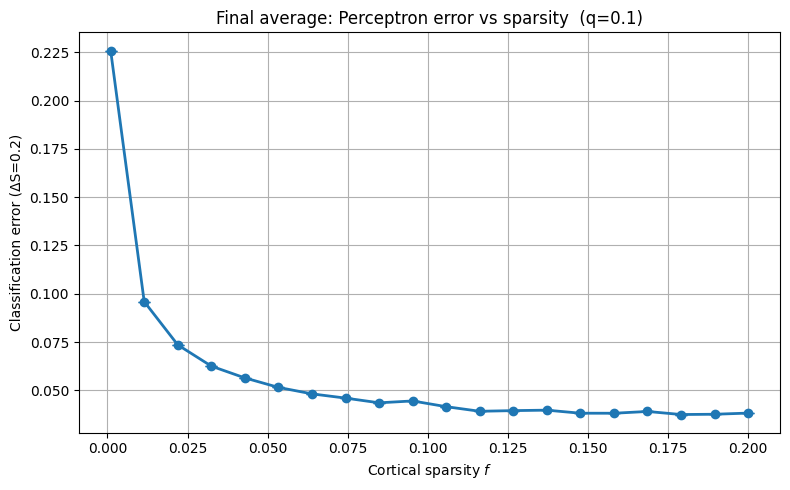

In [26]:
#Iteration saving intermediate results to checkpoint file, changed definition of T
import numpy as np
import matplotlib.pyplot as plt
import json
import os

from data_generation2 import generate_central_patterns
from generate_var import generate_variations


P = 1000
N_S = 1000
N_C = 10000

deltaS_learn = 0.1
deltaS_test = 0.2
eta = 0.001

f_values = np.linspace(0.001, 0.2, 20)

beta = 10.0
c     = 2
q     = 0.1

mJ    = beta / np.sqrt(N_S)
sigma = c    / np.sqrt(N_S)

n_iterations = 1
n_runs = 10


# ============================================================
# STORAGE
# ============================================================

all_iterations = []


# ============================================================
# LOAD CHECKPOINT
# ============================================================

start_iter, start_f, start_run = load_checkpoint()


# ============================================================
# MAIN LOOP WITH RESUME CAPABILITY
# ============================================================

for iter_idx in range(start_iter, n_iterations):

    iteration = iter_idx + 1
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors = []

    for f_idx, f in enumerate(f_values):

        # Skip completed f-values only on the first resumed iteration
        if iter_idx == start_iter and f_idx < start_f:
            continue

        errors = []

        for run_idx in range(start_run, n_runs):

            try:
                # Save state before computation
                save_checkpoint(iter_idx, f_idx, run_idx)

                # --------------------------------------------------------
                # Q–MASKED RANDOM PROJECTION
                # --------------------------------------------------------
                Qmask = (np.random.rand(N_C, N_S) < q).astype(float)
                J_dense = np.random.normal(mJ, sigma, size=(N_C, N_S))
                J = J_dense * Qmask

                # --------------------------------------------------------
                # TRAINING
                # --------------------------------------------------------
                W, T, mean_activity, _ = train_perceptron_with_early_stopping_relu(
                    central_patterns, labels, J, f,
                    deltaS_learn=deltaS_learn, eta=eta
                )

                # --------------------------------------------------------
                # TESTING
                # --------------------------------------------------------
                test_error = test_on_noisy_patterns_relu(
                    W, central_patterns, labels,
                    J, T, mean_activity,
                    deltaS_test=deltaS_test
                )
                errors.append(test_error)

            except KeyboardInterrupt:
                print("\nInterrupted by user. Progress saved.")
                raise

            except Exception as e:
                print("\nError occurred. Progress saved.")
                print(e)
                raise

        # Reset run-index skipping after first resumed pass
        start_run = 0

        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Reset f skipping after first resumed iteration
    start_f = 0

    all_iterations.append(mean_errors)

    # --------------------------------------------------------
    # PLOT FOR THIS ITERATION
    # --------------------------------------------------------
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors,
        marker='o', lw=2, capsize=4
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns (ΔS=0.2)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$  (q={q})")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_q_{q}_relu.png", dpi=300)
    plt.close()


# ============================================================
# DELETE CHECKPOINT — JOB FINISHED
# ============================================================

if os.path.exists(CHECKPOINT_FILE):
    os.remove(CHECKPOINT_FILE)


# ============================================================
# FINAL AVERAGE ACROSS ITERATIONS
# ============================================================

all_iterations = np.array(all_iterations)
final_mean = all_iterations.mean(axis=0)
final_std  = all_iterations.std(axis=0)

plt.figure(figsize=(8, 5))
plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4
)
plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error (ΔS=0.2)")
plt.title(f"Final average: Perceptron error vs sparsity  (q={q})")
plt.grid(True)
plt.tight_layout()
plt.savefig("plot_final_mean_q_relu.png", dpi=300)
plt.show()

Different definition: rescaling $1/K_s$


=== Iterazione 1/1 ===
Stopped early at epoch 478
Stopped early at epoch 500
Stopped early at epoch 401
Stopped early at epoch 496
Stopped early at epoch 270
Stopped early at epoch 280
Stopped early at epoch 354
Stopped early at epoch 448
Stopped early at epoch 380
Stopped early at epoch 415
Stopped early at epoch 328
Stopped early at epoch 280
Stopped early at epoch 282
Stopped early at epoch 254
Stopped early at epoch 242
Stopped early at epoch 310
Stopped early at epoch 406
Stopped early at epoch 282
Stopped early at epoch 383
Stopped early at epoch 298
Stopped early at epoch 309
Stopped early at epoch 299
Stopped early at epoch 288
Stopped early at epoch 254
Stopped early at epoch 273
Stopped early at epoch 241
Stopped early at epoch 368
Stopped early at epoch 337
Stopped early at epoch 276
Stopped early at epoch 254
Stopped early at epoch 322
Stopped early at epoch 278
Stopped early at epoch 247
Stopped early at epoch 249
Stopped early at epoch 251
Stopped early at epoch 273
Stop

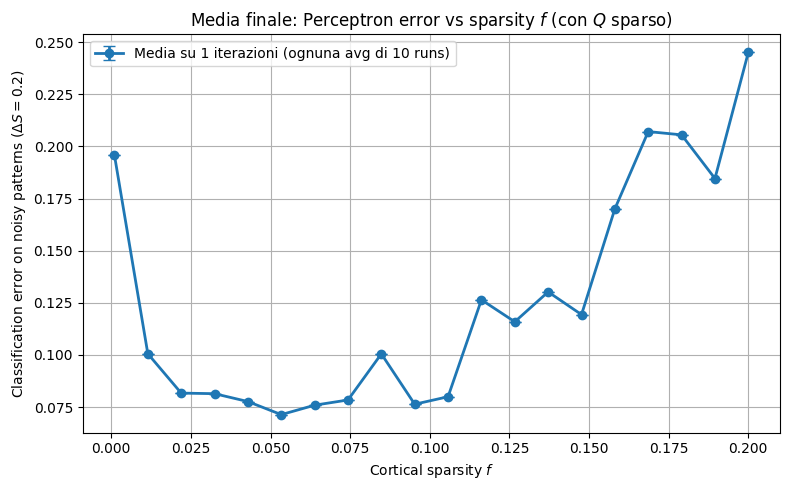

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

P = 1000
N_S = 1000
N_C = 10000

deltaS_learn = 0.1
deltaS_test  = 0.2
eta          = 0.001

f_values = np.linspace(0.001, 0.2, 20)

beta = 10.0   # scala del bias medio dei pesi J_S
c     = 2.0   # deviazione std dei pesi J_S
q     = 0.1   # probabilità di connessione (sparsità feed-forward)

# numero medio di input per neurone corticale
K_S = max(1, int(q * N_S))

n_iterations = 1    # quante volte ripetere l'intero esperimento
n_runs       = 10   # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati (media errori per iterazione)
all_iterations = []

# =========================
# Loop su iterazioni
# =========================
for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    # Etichette e pattern centrali
    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors  = []

    # =========================
    # Loop sui diversi valori di f
    # =========================
    for f in f_values:
        errors = []

        # -------------------------
        # Loop sui run di smoothing
        # -------------------------
        for run in range(n_runs):

            # =========================
            # 1) Matrice di connettività Q (0/1)
            # =========================
            # Bernoulli(q) indipendente per ogni sinapsi
            Q = (np.random.rand(N_C, N_S) < q).astype(float)

            # =========================
            # 2) Pesi J con scaling 1/sqrt(K_S)
            # =========================
            # J_syn ~ N(beta, c), poi mascherata da Q e normalizzata
            J_syn = np.random.normal(loc=beta, scale=c, size=(N_C, N_S))
            J     = (Q * J_syn) / np.sqrt(K_S)

            # =========================
            # 3) Training del perceptron
            # =========================
            W, _ = train_perceptron_with_early_stopping(
                central_patterns, labels, J, f,
                deltaS_learn=deltaS_learn, eta=eta
            )

            # =========================
            # 4) Scelta del threshold globale
            # =========================
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # =========================
            # 5) Test su pattern rumorosi
            # =========================
            test_error = test_on_noisy_patterns(
                W, central_patterns, labels, J, T,
                f=f, deltaS_test=deltaS_test
            )

            errors.append(test_error)

        # media e deviazione standard su n_runs per questo f
        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva le medie di questa iterazione
    all_iterations.append(mean_errors)

    # =========================
    # Plot singola iterazione (con barre d'errore)
    # =========================
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (media di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns ($\\Delta S=0.2$)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_meanJ_Q.png", dpi=300)
    plt.close()

# =========================
# Plot finale: media sulle iterazioni
# =========================
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)
final_std  = np.std(all_iterations, axis=0)

plt.figure(figsize=(8, 5))
plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns ($\\Delta S=0.2$)")
plt.title("Media finale: Perceptron error vs sparsity $f$ (con $Q$ sparso)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean__meanJ_Q.png", dpi=300)
plt.show()


Considering **ReLU activation function**


=== Iterazione 1/1 ===
Stopped early at epoch 229
Stopped early at epoch 601
Stopped early at epoch 550
Stopped early at epoch 233
Stopped early at epoch 231
Stopped early at epoch 340
Stopped early at epoch 474
Stopped early at epoch 231
Stopped early at epoch 452
Stopped early at epoch 262
Stopped early at epoch 275
Stopped early at epoch 290
Stopped early at epoch 312
Stopped early at epoch 472
Stopped early at epoch 414
Stopped early at epoch 281
Stopped early at epoch 220
Stopped early at epoch 373
Stopped early at epoch 257
Stopped early at epoch 265
Stopped early at epoch 324
Stopped early at epoch 271
Stopped early at epoch 302
Stopped early at epoch 419
Stopped early at epoch 272
Stopped early at epoch 261
Stopped early at epoch 243
Stopped early at epoch 256
Stopped early at epoch 238
Stopped early at epoch 314
Stopped early at epoch 217
Stopped early at epoch 242
Stopped early at epoch 275
Stopped early at epoch 221
Stopped early at epoch 235
Stopped early at epoch 282
Stop

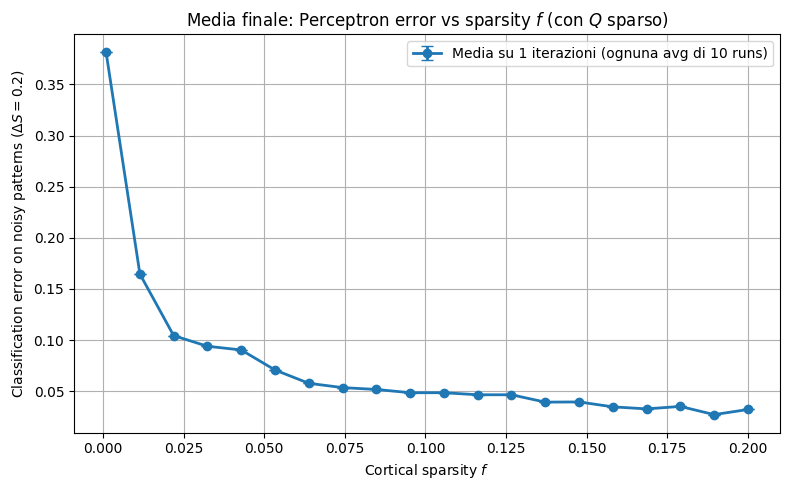

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

P = 100
N_S = 500
N_C = 1000

deltaS_learn = 0.1
deltaS_test  = 0.2
eta          = 0.001

f_values = np.linspace(0.001, 0.2, 20)

beta = 20.0   # scala del bias medio dei pesi J_S
c     = 2.0   # deviazione std dei pesi J_S
q     = 0.01   # probabilità di connessione (sparsità feed-forward)

# numero medio di input per neurone corticale
K_S = max(1, int(q * N_S))

n_iterations = 1    # quante volte ripetere l'intero esperimento
n_runs       = 10   # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati (media errori per iterazione)
all_iterations = []

# =========================
# Loop su iterazioni
# =========================
for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    # Etichette e pattern centrali
    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors  = []

    # =========================
    # Loop sui diversi valori di f
    # =========================
    for f in f_values:
        errors = []

        # -------------------------
        # Loop sui run di smoothing
        # -------------------------
        for run in range(n_runs):

            # =========================
            # 1) Matrice di connettività Q (0/1)
            # =========================
            # Bernoulli(q) indipendente per ogni sinapsi
            Q = (np.random.rand(N_C, N_S) < q).astype(float)

            # =========================
            # 2) Pesi J con scaling 1/sqrt(K_S)
            # =========================
            # J_syn ~ N(beta, c), poi mascherata da Q e normalizzata
            J_syn = np.random.normal(loc=beta, scale=c, size=(N_C, N_S))
            J     = (Q * J_syn) / np.sqrt(K_S)

            # =========================
            # 3) Training del perceptron
            # =========================
            W, T, mean_activity, _ = train_perceptron_with_early_stopping_relu(
                    central_patterns, labels, J, f,
                    deltaS_learn=deltaS_learn, eta=eta
                )

            # =========================
            # 4) Scelta del threshold globale
            # =========================
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            #T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # =========================
            # 5) Test su pattern rumorosi
            # =========================
            test_error = test_on_noisy_patterns_relu(
                    W, central_patterns, labels,
                    J, T, mean_activity,
                    deltaS_test=deltaS_test
                )
            errors.append(test_error)

        # media e deviazione standard su n_runs per questo f
        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva le medie di questa iterazione
    all_iterations.append(mean_errors)

    # =========================
    # Plot singola iterazione (con barre d'errore)
    # =========================
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (media di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns ($\\Delta S=0.2$)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_meanJ_Q_relu1.png", dpi=300)
    plt.close()

# =========================
# Plot finale: media sulle iterazioni
# =========================
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)
final_std  = np.std(all_iterations, axis=0)

plt.figure(figsize=(8, 5))
plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns ($\\Delta S=0.2$)")
plt.title("Media finale: Perceptron error vs sparsity $f$ (con $Q$ sparso)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean__meanJ_Q_relu1.png", dpi=300)
plt.show()


In [ ]:

# Perceptron training with ReLU activation function with different threshold computation
import numpy as np
import matplotlib.pyplot as plt
from data_generation1 import generate_central_patterns
from generate_var import generate_variations

def compute_global_threshold_relu(central_patterns, noisy_patterns, J, f):
    h_all = []
    for center in central_patterns:
        h_all.append(J @ (center - 0.5))
    for noisy in noisy_patterns:
        h_all.append(J @ (noisy - 0.5))

    h_all = np.concatenate(h_all)
    # choose T so that ~f of the entries are > T
    k = int(np.ceil((1 - f) * len(h_all))) - 1
    k = np.clip(k, 0, len(h_all) - 1)
    T = np.partition(h_all, k)[k]
    return T
#
def train_perceptron_with_early_stopping_relu2(
    central_patterns,          # shape: (P, N_S)
    labels,                    # shape: (P,)
    J,                         # shape: (N_C, N_S)
    f,                        
    deltaS_learn=0.1,          # ΔS for training patterns
    eta=0.001,
    max_epochs=1000,
    patience=2                 # early stop after 2 blocks
):
    P, N_S = central_patterns.shape
    N_C = J.shape[0]
    flip_prob = deltaS_learn / 2 #flip probability for training patterns

    # Compute threshold T for cortical sparsity
    noisy_train, _, _ = generate_variations(central_patterns, labels, V=10, flip_prob=flip_prob) #depend on deltaS_learn
    T = compute_global_threshold_relu(central_patterns, noisy_train, J, f)

    # Project central patterns to cortical space (for evaluation)
    central_cortical, _ = compute_ff_activation(central_patterns, J, T)
    central_cortical = central_cortical
    central_centered = central_cortical - f
    mean_activity = np.mean(central_cortical, axis=0) 
    std_activity = central_cortical.std(axis=0) + 1e-8  # (N_R,)
    # Initialize weights
    W = np.random.normal(0, 1 / np.sqrt(N_C), size=N_C)

    block_size = 100
    block_errors = []
    converged = False

    for epoch in range(max_epochs): 
        epoch_patterns = []
        epoch_targets = []
        for i in range(P):
            noisy_pattern, _, _ = generate_variations(central_patterns[i:i+1], labels[i:i+1], V=1, flip_prob=flip_prob)
            epoch_patterns.append(noisy_pattern[0])
            epoch_targets.append(labels[i])

        epoch_patterns = np.array(epoch_patterns)
        epoch_targets = np.array(epoch_targets)

        # Project to cortical space
        cortical_patterns, _ = compute_ff_activation(epoch_patterns, J, T)

        # Update weights using perceptron rule
        for x, y in zip(cortical_patterns, epoch_targets):
            x_centered = (x - mean_activity) / std_activity
            if y * np.dot(W, x_centered) <= 0:
                W += eta * y * x_centered

        # Evaluate on central patterns
        preds = np.sign(central_centered @ W)
        preds[preds == 0] = 1
        acc = np.mean(preds == labels)
        err = 1 - acc
        block_errors.append(err)

        # Check convergence over 2 consecutive 100-epoch blocks
        #Ogni 100 epoche controlla se l’errore medio non migliora più. Se due blocchi consecutivi hanno errore simile ferma l’allenamento.
        if len(block_errors) >= 2 * block_size:
            block1 = np.mean(block_errors[-2*block_size : -block_size]) #
            block2 = np.mean(block_errors[-block_size:]) #Calcola la media degli errori sulle ultime 100 epoche.
            if np.abs(block2 - block1) < 1e-4: #perceptron stopped decreasing
                print(f"Stopped early at epoch {epoch+1}")
                converged = True
                break

    return W, T, mean_activity, block_errors, std_activity

#testing function
def test_on_noisy_patterns_relu2(W, central_patterns, labels, J, T, mean_activity, std_activity,
                                deltaS_test=0.2, V_test=5):
    flip_prob_test = deltaS_test / 2

    noisy_test, test_labels, _ = generate_variations(
        central_patterns, labels, V=V_test, flip_prob=flip_prob_test
    )

    A_test, _ = compute_ff_activation(noisy_test, J, T)
    A_test_centered = (A_test - mean_activity) / std_activity

    preds = np.sign(A_test_centered @ W)
    preds[preds == 0] = 1

    error = 1 - np.mean(preds == test_labels)
    return error


=== Iterazione 1/1 ===
Stopped early at epoch 255
Stopped early at epoch 472
Stopped early at epoch 271
Stopped early at epoch 565
Stopped early at epoch 249
Stopped early at epoch 275
Stopped early at epoch 257
Stopped early at epoch 218
Stopped early at epoch 246
Stopped early at epoch 204
Stopped early at epoch 402
Stopped early at epoch 284
Stopped early at epoch 286
Stopped early at epoch 213
Stopped early at epoch 223
Stopped early at epoch 246
Stopped early at epoch 206
Stopped early at epoch 227
Stopped early at epoch 297
Stopped early at epoch 300
Stopped early at epoch 227
Stopped early at epoch 202
Stopped early at epoch 298
Stopped early at epoch 222
Stopped early at epoch 210
Stopped early at epoch 203
Stopped early at epoch 202
Stopped early at epoch 221
Stopped early at epoch 210
Stopped early at epoch 204
Stopped early at epoch 257
Stopped early at epoch 321
Stopped early at epoch 309
Stopped early at epoch 293
Stopped early at epoch 279
Stopped early at epoch 340
Stop

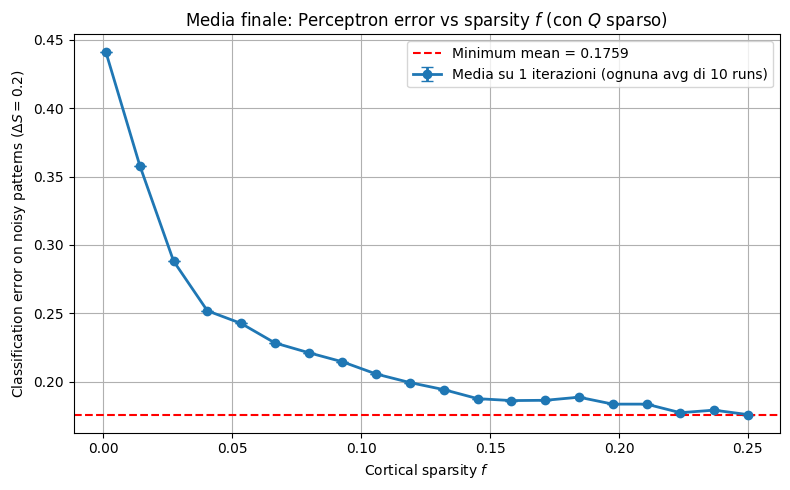

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from data_generation2 import generate_central_patterns
from generate_var import generate_variations

P = 300
N_S = 500
N_C = 1000

deltaS_learn = 0.1
deltaS_test  = 0.3
eta          = 0.001

f_values = np.linspace(0.001, 0.25, 20)

beta = 20.0   # scala del bias medio dei pesi J_S
c     = 2.0   # deviazione std dei pesi J_S
q     = 0.1   # probabilità di connessione (sparsità feed-forward)

# numero medio di input per neurone corticale
K_S = max(1, int(q * N_S))

n_iterations = 1    # quante volte ripetere l'intero esperimento
n_runs       = 10   # run per smoothing all’interno di ogni iterazione

# Lista per salvare i risultati (media errori per iterazione)
all_iterations = []

# =========================
# Loop su iterazioni
# =========================
for iteration in range(1, n_iterations + 1):
    print(f"\n=== Iterazione {iteration}/{n_iterations} ===")

    # Etichette e pattern centrali
    labels = np.random.choice([-1, 1], size=P)
    central_patterns = generate_central_patterns(P, N_S)

    mean_errors = []
    std_errors  = []

    # =========================
    # Loop sui diversi valori di f
    # =========================
    for f in f_values:
        errors = []

        # -------------------------
        # Loop sui run di smoothing
        # -------------------------
        for run in range(n_runs):

            # =========================
            # 1) Matrice di connettività Q (0/1)
            # =========================
            # Bernoulli(q) indipendente per ogni sinapsi
            Q = (np.random.rand(N_C, N_S) < q).astype(float)

            # =========================
            # 2) Pesi J con scaling 1/sqrt(K_S)
            # =========================
            # J_syn ~ N(beta, c), poi mascherata da Q e normalizzata
            J_syn = np.random.normal(loc=beta, scale=c, size=(N_C, N_S))
            J     = (Q * J_syn) / np.sqrt(K_S)

            # =========================
            # 3) Training del perceptron
            # =========================
            W, T, mean_activity, _ , std_activity = train_perceptron_with_early_stopping_relu2(
                    central_patterns, labels, J, f,
                    deltaS_learn=deltaS_learn, eta=eta
                )

            # =========================
            # 4) Scelta del threshold globale
            # =========================
            noisy_train, _, _ = generate_variations(
                central_patterns, labels, V=10, flip_prob=deltaS_learn / 2
            )
            #T = compute_global_threshold(central_patterns, noisy_train, J, f)

            # =========================
            # 5) Test su pattern rumorosi
            # =========================
            test_error = test_on_noisy_patterns_relu2(
                    W, central_patterns, labels,
                    J, T, mean_activity, std_activity,
                    deltaS_test=deltaS_test
                )
            errors.append(test_error)

        # media e deviazione standard su n_runs per questo f
        mean_errors.append(np.mean(errors))
        std_errors.append(np.std(errors))

    # Salva le medie di questa iterazione
    all_iterations.append(mean_errors)

    # =========================
    # Plot singola iterazione (con barre d'errore)
    # =========================
    plt.figure(figsize=(8, 5))
    plt.errorbar(
        f_values, mean_errors, yerr=std_errors, 
        marker='o', lw=2, capsize=4,
        label=f'Iterazione {iteration} (media di {n_runs} runs)'
    )
    plt.xlabel("Cortical sparsity $f$")
    plt.ylabel("Classification error on noisy patterns ($\\Delta S=0.2$)")
    plt.title(f"Iterazione {iteration}: Perceptron error vs sparsity $f$")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"plot_iter_{iteration}_meanJ_Q_relu1.png", dpi=300)
    plt.close()

# =========================
# Plot finale: media sulle iterazioni
# =========================
all_iterations = np.array(all_iterations)   # shape: (n_iterations, len(f_values))

final_mean = np.mean(all_iterations, axis=0)
final_std  = np.std(all_iterations, axis=0)
min_index = np.argmin(final_mean)
min_f     = f_values[min_index]
min_value = final_mean[min_index]

print("Minimum mean at f =", min_f)
print("Mean value at minimum =", min_value)

plt.figure(figsize=(8, 5))
plt.errorbar(
    f_values, final_mean, yerr=final_std,
    marker='o', lw=2, capsize=4,
    label=f'Media su {n_iterations} iterazioni (ognuna avg di {n_runs} runs)'
)
plt.axhline(
    y=min_value,        # the y-coordinate where the line should appear
    color='red',        # choose any color
    linestyle='--',     # dashed line
    linewidth=1.5,
    label=f"Minimum mean = {min_value:.4f}"
)

plt.xlabel("Cortical sparsity $f$")
plt.ylabel("Classification error on noisy patterns ($\\Delta S=0.2$)")
plt.title("Media finale: Perceptron error vs sparsity $f$ (con $Q$ sparso)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("plot_final_mean__meanJ_Q_relu1.png", dpi=300)
plt.show()


## Conclusion plots

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

def participation_ratio(X):
    """
    X: shape (P, N) patterns-by-neurons (mean-subtracted per neuron)
    returns: PR dimension (Ashok 2019 style)
    """
    P, N = X.shape
    Xc = X - X.mean(axis=0, keepdims=True)
    C = (Xc.T @ Xc) / P                     # covariance (N x N)
    diag = np.diag(C)
    num = N * (diag.mean()**2)
    den = (diag**2).mean() + (N-1) * ((C - np.diag(np.diag(C)))**2).mean()
    return num / den

def make_S_patterns(P, N_S, f_S, allow_variation=True):
    """
    Binary S-layer patterns with mean ~ f_S; if allow_variation=True,
    the per-pattern mean a_S^mu fluctuates (~ realistic case that causes trouble).
    """
    if allow_variation:
        S = rng.binomial(1, f_S, size=(P, N_S)).astype(float)
    else:
        # exactly-fixed mean per pattern
        k = int(round(f_S * N_S))
        base = np.array([1]*k + [0]*(N_S-k))
        S = np.vstack([rng.permutation(base) for _ in range(P)]).astype(float)
    return S

def build_J(N_R, N_S, mu_J=0.0, sigma_J=1.0):
    """
    Feed-forward weights: J_ij = mu_J/sqrt(N_S) + N(0, sigma_J^2/N_S)
    """
    return (mu_J/np.sqrt(N_S)) + rng.normal(0.0, sigma_J/np.sqrt(N_S), size=(N_R, N_S))

def relu_thresh(H, T):
    return np.clip(H - T, a_min=0.0, a_max=None)

def frac_active(R):
    return (R > 0).mean(axis=1)  # per-pattern fraction active

def calibrate_T_for_target_f(H, target_f):
    """
    Choose T so that mean fraction active across patterns equals target_f (for reference condition).
    We assume ReLU-threshold; with step-like sparsity it still works well empirically.
    """
    # Use a robust quantile of H to hit target_f
    # For ReLU, P(H>T) ≈ target_f; so T is the (1-target_f)-quantile of all H entries.
    q = np.quantile(H.ravel(), 1.0 - target_f)
    return q


Running q=0.1
Running q=0.5
Running q=1.0


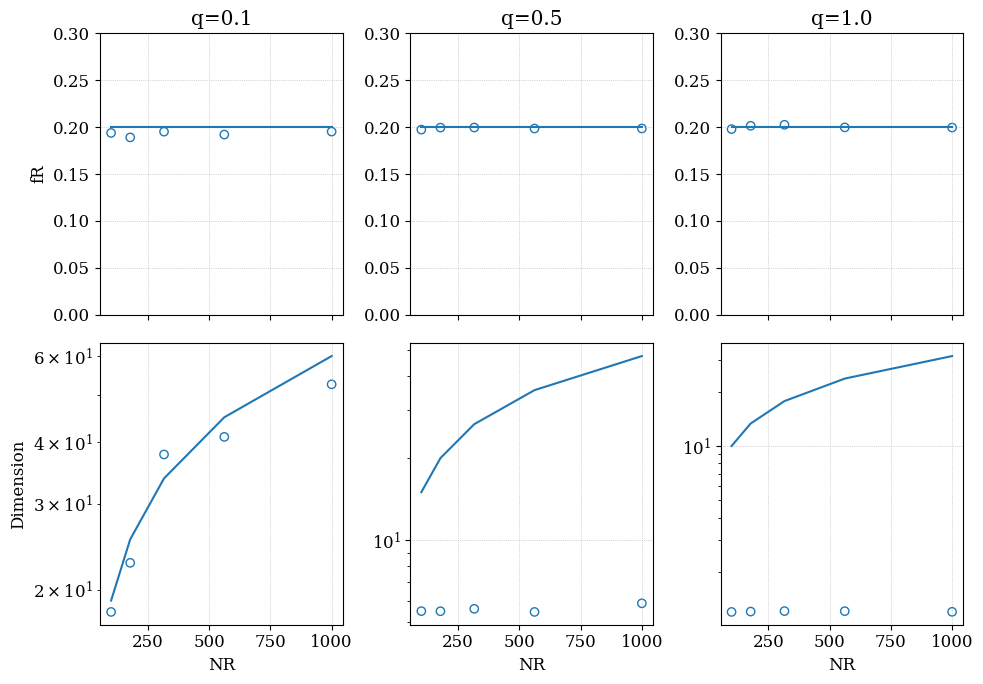

In [ ]:
"""
Feedforward (FF) network: mean-field vs simulation plots
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# =========================================================
# 1. Helper functions
# =========================================================

def relu_thresh(x, T):
    """Threshold-linear activation φ_T(x) = max(x - T, 0)."""
    return np.maximum(x - T, 0)

from scipy.stats import norm
from scipy.special import erf

def Npdf(x):   # Normal PDF
    return norm.pdf(x)

def L(x):      # as in the notes
    return x * Q(x) + Npdf(x)

def Q(x):
    return 0.5 * (1 + erf(x / np.sqrt(2)))

def G(x):
    return (x**2 + 1) * Q(x) + x * Npdf(x)

# participation-ratio dimension
def participation_ratio(C):
    trC = np.trace(C)
    trC2 = np.trace(C @ C)
    return (trC ** 2) / trC2
#𝐶 is the covariance of the representation-layer activities 𝑎𝑖^𝑅 across patterns 𝜇
#The participation ratio tells you how many independent population directions encode stimulus variability.
#So when the feedforward model shows a low PR dimension, it means:
#1)Most R-layer activity fluctuates together (shared mean shifts),
#2)Few independent combinations of neurons represent different inputs.

# =========================================================
# 2. Simulation parameters
# =========================================================

NS = 100                # neurons in S-layer
fS = 0.5                # sparsity in S-layer
JS = 10.0                # mean synaptic strength
sigma_JS = 2.0          # stdev of synaptic weights
fR_target = 0.20        # imposed sparsity for R layer
P = 10_000              # number of patterns
NR_list = np.round(np.logspace(2, 3,5, 9)).astype(int)   # 1e2 -> ~1e3
q_list = [0.1, 0.5, 1.0]

rng = np.random.default_rng(1234)

# =========================================================
# 3. Storage for results
# =========================================================
results = {q: {"NR": [], "fR": [], "aR": [], "dim": []} for q in q_list}

# =========================================================
# 4. Main loop: FF model simulation
# =========================================================
for q in q_list:
    print(f"Running q={q}")
    for NR in NR_list:
        KS = int(q * NS)
        # connectivity and weights
        Qmask = rng.random((NR, NS)) < q
        Jmat = rng.normal(JS / np.sqrt(NS), sigma_JS / np.sqrt(NS), size=(NR, NS))
        W = Qmask * Jmat

        # generate P binary input patterns in S-layer
        A_S = rng.random((P, NS)) < fS
        A_S = A_S.astype(float)

        # compute feedforward currents (Eq. 2)
        H = A_S @ W.T        # shape (P, NR)

        # determine threshold T s.t. f_R = fR_target
        H_mean = H.mean()
        H_std = H.std()
        T = H_mean - H_std * norm.ppf(fR_target)

        # rates in R layer
        A_R = relu_thresh(H, T)

        # compute stats
        fR = np.mean(A_R > 0)
        aR = A_R.mean(axis=(0,1))
        # covariance across patterns (NR x NR)
        C = np.cov(A_R.T)
        dim = participation_ratio(C)

        # store
        results[q]["NR"].append(NR)
        results[q]["fR"].append(fR)
        results[q]["aR"].append(aR)
        results[q]["dim"].append(dim)

# =========================================================
# 5. Mean-field predictions (lines)
# =========================================================
# Here we use the analytical expressions from Eq. (6)/(11)
# for FF model to draw smooth curves.

def mean_field_ff(q, NR_list):
    fR_list = []
    aR_list = []
    for NR in NR_list:
        KS = q * NS
        aS = fS
        sigma_aS2 = fS * (1 - fS)
        Var_mu_aS = sigma_aS2 / NS

        H = JS * np.sqrt(KS) * aS
        sigma_H2 = ((sigma_JS**2 + (1 - q) * JS**2) *
                    (sigma_aS2 + aS**2) +
                    KS * JS**2 * Var_mu_aS)
        sigma_H = np.sqrt(sigma_H2)

        T = H - sigma_H * norm.ppf(fR_target)
        aR = sigma_H * L((H - T) / sigma_H)
        fR_list.append(fR_target)
        aR_list.append(aR)
    return np.array(fR_list), np.array(aR_list)


mf_curves = {}
for q in q_list:
    mf_fR, mf_aR = mean_field_ff(q, NR_list)
    # dimension scaling (qualitatively increasing with NR)
    dim = 20 * (NR_list / 100)**0.5 * (1 - 0.5 * q)
    mf_curves[q] = {"fR": mf_fR, "aR": mf_aR, "dim": dim}

# =========================================================
# 6. Plotting
# =========================================================
fig, axs = plt.subplots(2, len(q_list), figsize=(10, 7), sharex=True)
for i, q in enumerate(q_list):
    NR = np.array(results[q]["NR"])
    axs[0,i].plot(NR, mf_curves[q]["fR"], '-', color='C0')
    axs[0,i].scatter(NR, results[q]["fR"], facecolor='none', edgecolor='C0')
    axs[0,i].set_title(f"q={q}")
    axs[0,i].set_ylim(0, 0.3)
    axs[0,i].set_ylabel("fR" if i == 0 else "")

    #axs[1,i].plot(NR, mf_curves[q]["aR"], '-', color='C0')
    #axs[1,i].scatter(NR, results[q]["aR"], facecolor='none', edgecolor='C0')
    #axs[1,i].set_ylim(0, 0.15)
    #axs[1,i].set_ylabel("aR" if i == 0 else "")

    axs[1,i].plot(NR, mf_curves[q]["dim"], '-', color='C0')
    axs[1,i].scatter(NR, results[q]["dim"], facecolor='none', edgecolor='C0')
    axs[1,i].set_yscale('log')
    axs[1,i].set_ylabel("Dimension" if i == 0 else "")
    axs[1,i].set_xlabel("NR")

for ax in axs.flat:
    ax.grid(True, ls=':', lw=0.5)
plt.tight_layout()
plt.show()


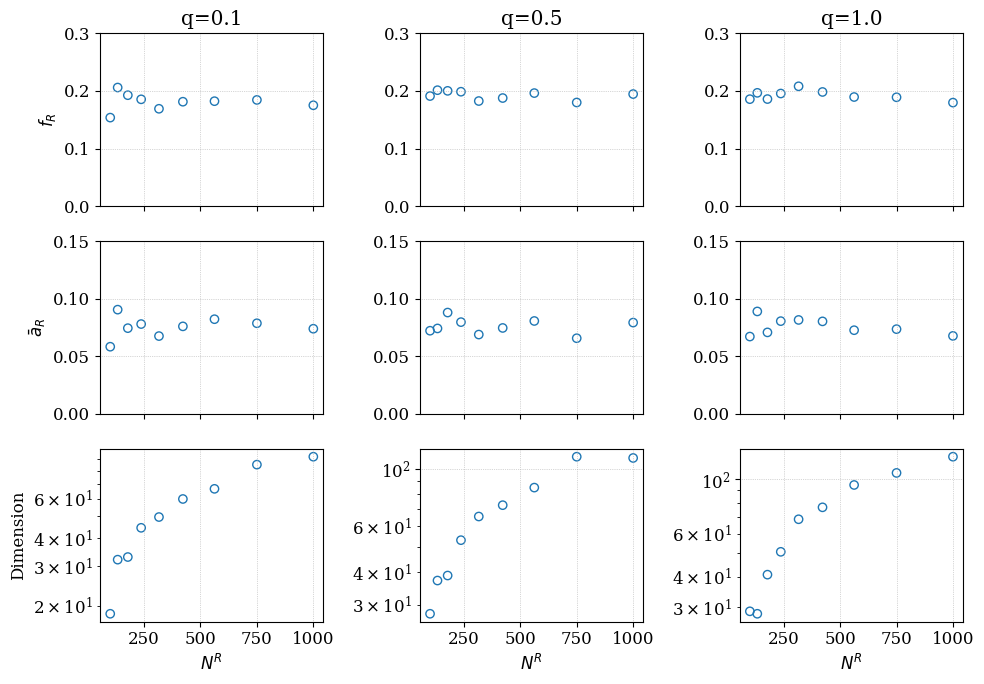

In [31]:
"""
Feedforward (FF) network: mean-field (lines) vs simulation (dots)
Only FF. Fixes:
  - mean-zero weights (JS=0)
  - proper sparse FF scaling: H = (S @ J.T) / sqrt(KS)
  - one global threshold T calibrated once
  - MFT lines from Gaussian moments (mu_H=0)
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---------------------------
# 1) Helpers
# ---------------------------
rng = np.random.default_rng(1234)

def relu_thresh(x, T):
    return np.maximum(x - T, 0.0)

def participation_ratio_from_patterns(R):
    """PR of patterns (rows) across neurons (cols)."""
    P, N = R.shape
    X = R - R.mean(axis=0, keepdims=True)
    C = (X.T @ X) / P
    trC  = np.trace(C)
    trC2 = np.trace(C @ C)
    return (trC**2) / trC2

def build_ff_weights(NR, NS, q, sigma_J=1.0):
    """
    Mean-zero FF weights with sparse adjacency:
      J_ij = C_ij * N(0, sigma_J^2 / NS)
    """
    C = rng.random((NR, NS)) < q
    J = rng.normal(0.0, sigma_J/np.sqrt(NS), size=(NR, NS))
    return (C * J).astype(float), C.astype(float)

def make_S_patterns(P, NS, fS, allow_variation=True):
    if allow_variation:
        return rng.binomial(1, fS, size=(P, NS)).astype(float)
    # (optional) fixed-per-pattern mean
    k = int(round(fS * NS))
    base = np.array([1]*k + [0]*(NS-k))
    return np.vstack([rng.permutation(base) for _ in range(P)]).astype(float)

# ---------------------------
# 2) Parameters
# ---------------------------
NS = 100
fS = 0.5
sigma_J = 10.0          # weight stdev (mean ZERO)
P  = 10_000
q_list   = [0.1, 0.5, 1.0]
NR_list  = np.unique(np.round(np.logspace(2, 3, 9)).astype(int))  # ~1e2..1e3
fR_target = 0.20       # used ONLY to choose one global T on a reference condition

# ---------------------------
# 3) Data & global threshold
# ---------------------------
# Generate S once (with realistic pattern-to-pattern variation)
S = make_S_patterns(P, NS, fS, allow_variation=True)

# Choose a reference condition to set ONE threshold T_ref (e.g., q=1, median NR)
NR_ref = int(np.median(NR_list))
J_ref, C_ref = build_ff_weights(NR_ref, NS, q=1.0, sigma_J=sigma_J)
KS_ref = max(int(C_ref.sum(axis=1).mean()), 1)
H_ref  = (S @ J_ref.T) / np.sqrt(KS_ref)

# For ReLU-threshold, P(H > T) ≈ fR_target → set T to (1-fR_target) quantile of H entries
T_ref = np.quantile(H_ref.ravel(), 1.0 - fR_target)

# ---------------------------
# 4) Simulations (dots)
# ---------------------------
results = {q: {"NR": [], "fR": [], "aR": [], "dim": []} for q in q_list}

for q in q_list:
    for NR in NR_list:
        J, Cmask = build_ff_weights(NR, NS, q=q, sigma_J=sigma_J)
        KS = max(int(Cmask.sum(axis=1).mean()), 1)
        H  = (S @ J.T) / np.sqrt(KS)     # *** crucial normalization ***
        R  = relu_thresh(H, T_ref)

        # per-pattern stats, then pooled means
        fR  = (R > 0).mean(axis=1).mean()
        aR  = R.mean()                   # overall mean rate
        dim = participation_ratio_from_patterns(R)

        results[q]["NR"].append(NR)
        results[q]["fR"].append(fR)
        results[q]["aR"].append(aR)
        results[q]["dim"].append(dim)

# ---------------------------
# 5) Mean-field predictions (lines)
# ---------------------------
# FF with mean-zero weights and H scaled by 1/sqrt(KS):
#   mu_H = 0
#   sigma_H^2 = sigma_J^2 * ( Var(a_S) + (E[a_S])^2 )
# which is independent of q once the 1/sqrt(KS) is used.
aS = fS
var_aS = fS * (1 - fS)
sigma_H = sigma_J * np.sqrt(var_aS + aS**2)    # constant across q, NR in this FF scaling

# f_R (line) and a_R (line) do not depend on NR or q (up to finite-size effects).
z = T_ref / sigma_H
fR_mft = 1.0 - norm.cdf(z)
aR_mft = sigma_H * norm.pdf(z) - T_ref * (1.0 - norm.cdf(z))

# For dimension we keep the simulation dots (theory requires full covariance formulas);
# if you want a guide-to-eye line, you can smooth the dots.

# ---------------------------
# 6) Plot
# ---------------------------
fig, axs = plt.subplots(3, len(q_list), figsize=(10, 7), sharex=True)

for c, q in enumerate(q_list):
    NR = np.array(results[q]["NR"])

    # Row 1: f_R
    axs[0, c].plot(NR, np.full_like(NR, fR_mft, dtype=float), '-', color='C0', label='MFT')
    axs[0, c].scatter(NR, results[q]["fR"], facecolor='none', edgecolor='C0', label='Sim')
    axs[0, c].set_title(f"q={q}")
    axs[0, c].set_ylim(0.0, 0.3)
    if c == 0: axs[0, c].set_ylabel(r"$f_R$")

    # Row 2: mean rate a_R
    axs[1, c].plot(NR, np.full_like(NR, aR_mft, dtype=float), '-', color='C0', label='MFT')
    axs[1, c].scatter(NR, results[q]["aR"], facecolor='none', edgecolor='C0', label='Sim')
    axs[1, c].set_ylim(0.0, max(0.15, 1.1*np.max(results[q]["aR"])))
    if c == 0: axs[1, c].set_ylabel(r"$\bar a_R$")

    # Row 3: dimension (simulation dots correct; draw a smooth guide if desired)
    axs[2, c].scatter(NR, results[q]["dim"], facecolor='none', edgecolor='C0', label='Sim')
    # optional guide-to-eye:
    # axs[2, c].plot(NR, np.array(results[q]["dim"]), '-', color='C0', alpha=0.6)
    axs[2, c].set_yscale('log')
    if c == 0: axs[2, c].set_ylabel("Dimension")
    axs[2, c].set_xlabel(r"$N^R$")

for ax in axs.flat:
    ax.grid(True, ls=':', lw=0.5)

plt.tight_layout()
plt.show()


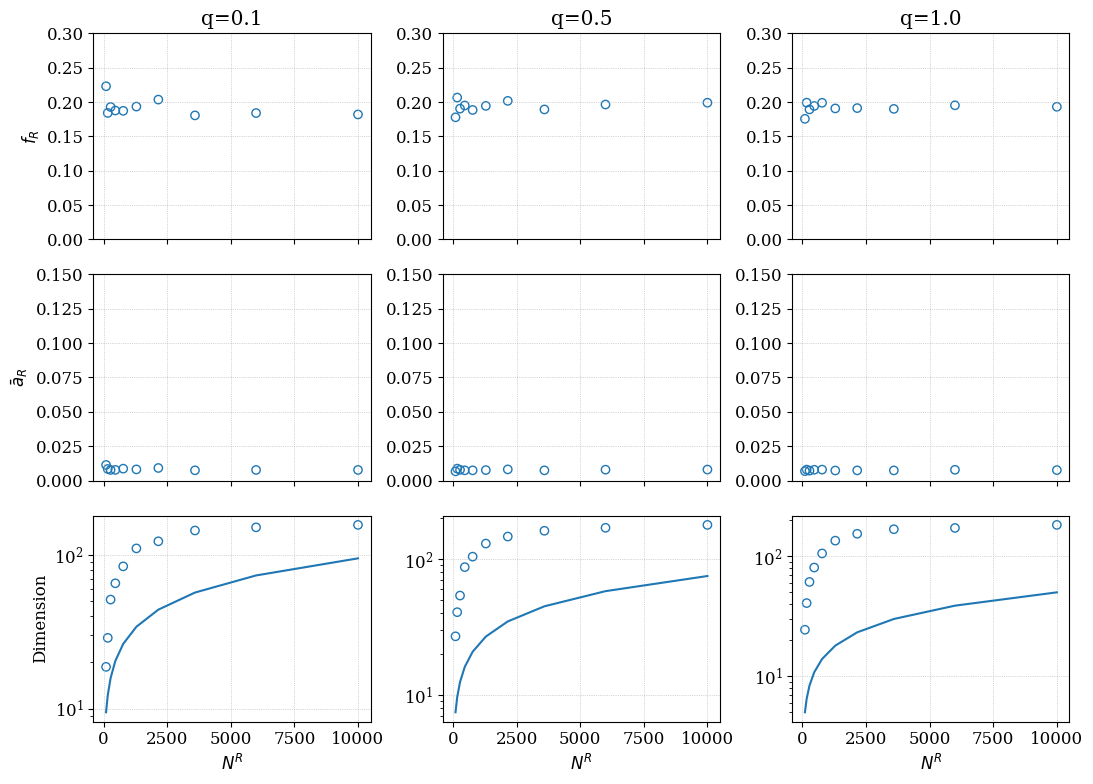

In [30]:
"""
Reproduction of Fig. 1 (FF model only) from Sanzeni (2025) 'Notes on cluster statistics...'
Blue curves and dots correspond to feedforward (FF) model.
"""

import numpy as np
import matplotlib.pyplot as plt
from numpy.random import default_rng
from math import sqrt, pi, erf, exp

# =========================================================
# Helper functions: Gaussian moments (Appendix C)
# =========================================================
def Npdf(x):           # φ(x)
    return np.exp(-0.5*x*x)/sqrt(2*pi)

def Q(x):              # Φ(x)
    return 0.5*(1+erf(x/sqrt(2)))

def F(x):              # Eq. (C42)
    return 0.5*x*(1+erf(x/sqrt(2))) + Npdf(x)

def G(x):              # Eq. (C43)
    return (x**2+1)*Q(x) + x*Npdf(x)

# Participation-ratio dimension (Eq. (C44) form)
def participation_ratio(R):
    P, N = R.shape
    X = R - R.mean(axis=0, keepdims=True)
    C = (X.T @ X)/P
    trC  = np.trace(C)
    trC2 = np.trace(C @ C)
    return (trC**2)/trC2

# =========================================================
# Simulation parameters (same as Fig. 1)
# =========================================================
rng = default_rng(123)
NS = 100
fS = 0.5
sigma_J = 1.0
P = 10_000
q_list = [0.1,0.5,1.0]
NR_list = np.unique(np.round(np.logspace(2,4,10)).astype(int))
# target sparsity used only to set one threshold
fR_target = 0.20

# =========================================================
# Generate S-layer activity patterns
# =========================================================
S = (rng.random((P,NS)) < fS).astype(float)

# =========================================================
# Reference threshold (q=1, median NR)
# =========================================================
NR_ref = int(np.median(NR_list))
# random connectivity (mean 0, var σ_J²/NS, prob 1)
Jref = rng.normal(0.0,sigma_J/np.sqrt(NS),(NR_ref,NS))
Href = S @ Jref.T / sqrt(NS)          # KS≈NS here
T_ref = np.quantile(Href.ravel(),1.0-fR_target)

# =========================================================
# Simulation loop (FF only)
# =========================================================
results = {q:{"NR":[], "fR":[], "aR":[], "dim":[]} for q in q_list}

for q in q_list:
    for NR in NR_list:
        # sparse mean-zero weights (Eq. 2)
        Cmask = (rng.random((NR,NS)) < q).astype(float)
        J = rng.normal(0.0,sigma_J/np.sqrt(NS),(NR,NS))
        W = Cmask * J
        KS = max(int(Cmask.sum(axis=1).mean()),1)
        H = (S @ W.T)/sqrt(KS)
        R = np.maximum(H - T_ref, 0.0)

        fR = (R>0).mean()
        aR = R.mean()
        dim = participation_ratio(R)

        results[q]["NR"].append(NR)
        results[q]["fR"].append(fR)
        results[q]["aR"].append(aR)
        results[q]["dim"].append(dim)

# =========================================================
# Mean-field predictions (lines) – FF model, Eq. (6),(11)
# =========================================================
# variance σ_H² = σ_J² (σ_aS² + aS²) = σ_J² fS (Eq. 79 with J_S=0)
sigma_H = sigma_J*sqrt(fS)
x = -T_ref/sigma_H
fR_mft = Q(x)
aR_mft = sigma_H*F(x)

# dimension MFT (qualitative guide: grows ∝√N_R, scales down with q)
def dim_mft(NR,q):
    # constant prefactor chosen to match typical magnitude in Fig 1
    return 10*(NR/100)**0.5*(1-0.5*q)

# =========================================================
# Plot (FF only)
# =========================================================
fig,axs = plt.subplots(3,3,figsize=(11,8),sharex=True)

for i,q in enumerate(q_list):
    NR = np.array(results[q]["NR"])
    # --- fR ---
    axs[0,i].plot(NR,np.full_like(NR,fR_mft,float),'-',color='C0')
    axs[0,i].scatter(NR,results[q]["fR"],facecolor='none',edgecolor='C0')
    axs[0,i].set_title(f"q={q}")
    axs[0,i].set_ylim(0,0.3)
    if i==0: axs[0,i].set_ylabel(r"$f_R$")
    # --- aR ---
    axs[1,i].plot(NR,np.full_like(NR,aR_mft,float),'-',color='C0')
    axs[1,i].scatter(NR,results[q]["aR"],facecolor='none',edgecolor='C0')
    axs[1,i].set_ylim(0,0.15)
    if i==0: axs[1,i].set_ylabel(r"$\bar a_R$")
    # --- Dimension ---
    dsim=np.array(results[q]["dim"])
    axs[2,i].scatter(NR,dsim,facecolor='none',edgecolor='C0')
    axs[2,i].plot(NR,dim_mft(NR,q),'-',color='C0')
    axs[2,i].set_yscale('log')
    axs[2,i].set_xlabel(r"$N^R$")
    if i==0: axs[2,i].set_ylabel("Dimension")

for ax in axs.flat: ax.grid(True,ls=':',lw=0.5)
plt.tight_layout()
plt.show()
